In [ ]:
!pip install rasterio -q

import os
import glob
import re

import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import uniform_filter

DATA_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_MultiYear"

files = sorted(
    glob.glob(os.path.join(DATA_DIR, "*.tif"))
)

print("Number of GeoTIFF files:", len(files))

for f in files:
    print(os.path.basename(f))


def mean_filter(data, size):
    """
    Calculate local mean while ignoring NaN values.
    """

    valid = np.isfinite(data)

    data_filled = np.where(valid, data, 0)

    sum_values = uniform_filter(
        data_filled,
        size=size,
        mode="nearest"
    )

    count_values = uniform_filter(
        valid.astype(float),
        size=size,
        mode="nearest"
    )

    return np.divide(
        sum_values,
        count_values,
        out=np.full_like(sum_values, np.nan, dtype=float),
        where=count_values > 0
    )


def std_filter(data, size):
    """
    Calculate local standard deviation while ignoring NaN values.
    """

    valid = np.isfinite(data)

    data_filled = np.where(valid, data, 0)

    mean = mean_filter(data, size)

    mean_squared = uniform_filter(
        data_filled ** 2,
        size=size,
        mode="nearest"
    )

    count = uniform_filter(
        valid.astype(float),
        size=size,
        mode="nearest"
    )

    mean_squared = np.divide(
        mean_squared,
        count,
        out=np.full_like(mean_squared, np.nan, dtype=float),
        where=count > 0
    )

    variance = mean_squared - mean ** 2

    variance = np.maximum(variance, 0)

    return np.sqrt(variance)


Number of GeoTIFF files: 24
uhi_features_bengaluru_highland_monsoon_multiyear_30m.tif
uhi_features_bengaluru_highland_post_monsoon_multiyear_30m.tif
uhi_features_bengaluru_highland_summer_multiyear_30m.tif
uhi_features_bengaluru_highland_winter_multiyear_30m.tif
uhi_features_dehradun_montane_monsoon_multiyear_30m.tif
uhi_features_dehradun_montane_post_monsoon_multiyear_30m.tif
uhi_features_dehradun_montane_summer_multiyear_30m.tif
uhi_features_dehradun_montane_winter_multiyear_30m.tif
uhi_features_hyderabad_plateau_monsoon_multiyear_30m.tif
uhi_features_hyderabad_plateau_post_monsoon_multiyear_30m.tif
uhi_features_hyderabad_plateau_summer_multiyear_30m.tif
uhi_features_hyderabad_plateau_winter_multiyear_30m.tif
uhi_features_jodhpur_monsoon_multiyear_30m.tif
uhi_features_jodhpur_post_monsoon_multiyear_30m.tif
uhi_features_jodhpur_summer_multiyear_30m.tif
uhi_features_jodhpur_winter_multiyear_30m.tif
uhi_features_mumbai_coastal_monsoon_multiyear_30m.tif
uhi_features_mumbai_coastal_post_m

In [ ]:
all_dataframes = []

for file in files:

    print("\nProcessing:")
    print(os.path.basename(file))

    with rasterio.open(file) as src:

        # ------------------------------------------------
        # Read the 10 exported bands
        # ------------------------------------------------

        LST = src.read(1).astype(float)

        NDVI = src.read(2).astype(float)

        NDBI = src.read(3).astype(float)

        MNDWI = src.read(4).astype(float)

        Elevation = src.read(5).astype(float)

        doy_sin = src.read(6).astype(float)

        doy_cos = src.read(7).astype(float)

        Quality_Score = src.read(8).astype(float)

        Valid_Observation_Count = src.read(9).astype(float)

        Observation_Count = src.read(10).astype(float)


        # ------------------------------------------------
        # Replace nodata with NaN
        # ------------------------------------------------

        if src.nodata is not None:

            nodata = src.nodata

            LST[LST == nodata] = np.nan
            NDVI[NDVI == nodata] = np.nan
            NDBI[NDBI == nodata] = np.nan
            MNDWI[MNDWI == nodata] = np.nan
            Elevation[Elevation == nodata] = np.nan
            doy_sin[doy_sin == nodata] = np.nan
            doy_cos[doy_cos == nodata] = np.nan
            Quality_Score[Quality_Score == nodata] = np.nan
            Valid_Observation_Count[
                Valid_Observation_Count == nodata
            ] = np.nan
            Observation_Count[
                Observation_Count == nodata
            ] = np.nan


        # ------------------------------------------------
        # Neighborhood features
        # ------------------------------------------------

        NDVI_mean_3x3 = mean_filter(
            NDVI,
            size=3
        )

        NDBI_mean_5x5 = mean_filter(
            NDBI,
            size=5
        )

        NDBI_std_3x3 = std_filter(
            NDBI,
            size=3
        )

        NDVI_std_3x3 = std_filter(
            NDVI,
            size=3
        )

        MNDWI_mean_3x3 = mean_filter(
            MNDWI,
            size=3
        )


        # ------------------------------------------------
        # Flatten arrays
        # ------------------------------------------------

        LST_flat = LST.ravel()

        NDVI_flat = NDVI.ravel()

        NDBI_flat = NDBI.ravel()

        MNDWI_flat = MNDWI.ravel()

        Elevation_flat = Elevation.ravel()

        NDVI_mean_3x3_flat = NDVI_mean_3x3.ravel()

        NDBI_mean_5x5_flat = NDBI_mean_5x5.ravel()

        NDBI_std_3x3_flat = NDBI_std_3x3.ravel()

        NDVI_std_3x3_flat = NDVI_std_3x3.ravel()

        MNDWI_mean_3x3_flat = MNDWI_mean_3x3.ravel()

        doy_sin_flat = doy_sin.ravel()

        doy_cos_flat = doy_cos.ravel()


        # ------------------------------------------------
        # Create valid-pixel mask
        # ------------------------------------------------

        valid_mask = (

            np.isfinite(NDVI_flat) &

            np.isfinite(NDBI_flat) &

            np.isfinite(MNDWI_flat) &

            np.isfinite(Elevation_flat) &

            np.isfinite(NDVI_mean_3x3_flat) &

            np.isfinite(NDBI_mean_5x5_flat) &

            np.isfinite(NDBI_std_3x3_flat) &

            np.isfinite(NDVI_std_3x3_flat) &

            np.isfinite(MNDWI_mean_3x3_flat) &

            np.isfinite(doy_sin_flat) &

            np.isfinite(doy_cos_flat)
        )


        # ------------------------------------------------
        # Create DataFrame
        # ------------------------------------------------

        df_city = pd.DataFrame({

            "NDVI":
                NDVI_flat[valid_mask],

            "NDBI":
                NDBI_flat[valid_mask],

            "MNDWI":
                MNDWI_flat[valid_mask],

            "Elevation":
                Elevation_flat[valid_mask],

            "NDVI_mean_3x3":
                NDVI_mean_3x3_flat[valid_mask],

            "NDBI_mean_5x5":
                NDBI_mean_5x5_flat[valid_mask],

            "NDBI_std_3x3":
                NDBI_std_3x3_flat[valid_mask],

            "NDVI_std_3x3":
                NDVI_std_3x3_flat[valid_mask],

            "MNDWI_mean_3x3":
                MNDWI_mean_3x3_flat[valid_mask],

            "doy_sin":
                doy_sin_flat[valid_mask],

            "doy_cos":
                doy_cos_flat[valid_mask],

            # Keep LST separately for later UHI analysis
            "LST":
                LST_flat[valid_mask]
        })


        # ------------------------------------------------
        # Extract city and season from filename
        # ------------------------------------------------

        filename = os.path.basename(file)

        df_city["source_file"] = filename

        if "nagpur_composite" in filename:
            df_city["city"] = "Nagpur"

        elif "mumbai_coastal" in filename:
            df_city["city"] = "Mumbai"

        elif "hyderabad_plateau" in filename:
            df_city["city"] = "Hyderabad"

        elif "bengaluru_highland" in filename:
            df_city["city"] = "Bengaluru"

        elif "dehradun_montane" in filename:
            df_city["city"] = "Dehradun"

        elif "jodhpur" in filename:
            df_city["city"] = "Dehradun"

        else:
            df_city["city"] = "Unknown"


        # ------------------------------------------------
        # Extract season
        # ------------------------------------------------

        if "summer" in filename:
            df_city["season"] = "summer"

        elif "monsoon" in filename:
            df_city["season"] = "monsoon"

        elif "post_monsoon" in filename:
            df_city["season"] = "post_monsoon"

        elif "winter" in filename:
            df_city["season"] = "winter"

        else:
            df_city["season"] = "Unknown"


        # ------------------------------------------------
        # Store DataFrame
        # ------------------------------------------------

        all_dataframes.append(df_city)

        print(
            "Valid pixels:",
            len(df_city)
        )


Processing:
uhi_features_bengaluru_highland_monsoon_multiyear_30m.tif
Valid pixels: 1242091

Processing:
uhi_features_bengaluru_highland_post_monsoon_multiyear_30m.tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_summer_multiyear_30m.tif
Valid pixels: 1242109

Processing:
uhi_features_bengaluru_highland_winter_multiyear_30m.tif
Valid pixels: 1242109

Processing:
uhi_features_dehradun_montane_monsoon_multiyear_30m.tif
Valid pixels: 1034646

Processing:
uhi_features_dehradun_montane_post_monsoon_multiyear_30m.tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_summer_multiyear_30m.tif
Valid pixels: 1034906

Processing:
uhi_features_dehradun_montane_winter_multiyear_30m.tif
Valid pixels: 1034906

Processing:
uhi_features_hyderabad_plateau_monsoon_multiyear_30m.tif
Valid pixels: 1235605

Processing:
uhi_features_hyderabad_plateau_post_monsoon_multiyear_30m.tif
Valid pixels: 1242110

Processing:
uhi_features_hyderabad_plateau_summer_multiyear_30m.tif


In [ ]:
df = pd.concat(
    all_dataframes,
    ignore_index=True
)

print("\nFinal DataFrame shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())


Final DataFrame shape:
(27573959, 15)

Columns:
['NDVI', 'NDBI', 'MNDWI', 'Elevation', 'NDVI_mean_3x3', 'NDBI_mean_5x5', 'NDBI_std_3x3', 'NDVI_std_3x3', 'MNDWI_mean_3x3', 'doy_sin', 'doy_cos', 'LST', 'source_file', 'city', 'season']

First 5 rows:
       NDVI      NDBI     MNDWI  Elevation  NDVI_mean_3x3  NDBI_mean_5x5  \
0  0.714910 -0.267389 -0.480476      919.0       0.651544      -0.213916   
1  0.696875 -0.261294 -0.491264      918.0       0.683257      -0.239789   
2  0.746220 -0.330019 -0.465937      918.0       0.726954      -0.268488   
3  0.783540 -0.384277 -0.460268      918.0       0.775971      -0.306631   
4  0.791576 -0.390757 -0.458748      917.0       0.789989      -0.336714   

   NDBI_std_3x3  NDVI_std_3x3  MNDWI_mean_3x3   doy_sin   doy_cos        LST  \
0      0.053692      0.057669       -0.483133 -0.599551 -0.800336  33.964188   
1      0.067671      0.065706       -0.487368 -0.599551 -0.800336  34.244465   
2      0.073686      0.066441       -0.487041 -0.59955

In [ ]:
# ============================================================
# CHUNKED DISK-STREAMING PIPELINE (PEAK RAM < 500 MB)
# ============================================================
import os
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

INPUT_FILE = "/content/drive/MyDrive/UHI_Project/final_training_data_6cities.csv"
OUTPUT_DIR = "/content/drive/MyDrive/UHI_Project/final_feature_quality_results_chunked"
OUTPUT_PARQUET = os.path.join(OUTPUT_DIR, "features_relative_standardized.parquet")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Step 1: Pre-compute City x Season Elevation Baselines
# ------------------------------------------------------------
print("Phase 1: Scanning baseline elevation means...")
# Read only the 3 necessary columns to compute means without memory overhead
elev_lookup = {}
chunk_iter = pd.read_csv(
    INPUT_FILE,
    usecols=lambda c: c in ["city", "season", "Elevation"],
    chunksize=250_000
)

elev_sums = {}
elev_counts = {}

for chk in chunk_iter:
    if "city" in chk.columns and "season" in chk.columns:
        grouped = chk.groupby(["city", "season"])["Elevation"].agg(["sum", "count"])
        for (cty, ssn), row in grouped.iterrows():
            key = (cty, ssn)
            elev_sums[key] = elev_sums.get(key, 0.0) + row["sum"]
            elev_counts[key] = elev_counts.get(key, 0) + row["count"]
    else:
        elev_sums["global"] = elev_sums.get("global", 0.0) + chk["Elevation"].sum()
        elev_counts["global"] = elev_counts.get("global", 0) + chk["Elevation"].count()

if "global" in elev_sums:
    elev_lookup["global"] = elev_sums["global"] / max(elev_counts["global"], 1)
else:
    for key in elev_sums:
        elev_lookup[key] = elev_sums[key] / max(elev_counts[key], 1)

print(f"Computed elevation reference baselines for {len(elev_lookup)} scene(s).")
del elev_sums, elev_counts
gc.collect()

# ------------------------------------------------------------
# Step 2: Stream Chunks, Compute Features, and Write to Parquet
# ------------------------------------------------------------
print("\nPhase 2: Streaming, calculating features, and writing directly to disk...")

# Target sample per scene (matches your training balance)
SAMPLES_PER_SCENE = 60_000
scene_samples_collected = {}

FEATURES = [
    "delta_Elevation",
    "delta_NDBI",
    "delta_NDVI",
    "delta_MNDWI",
    "NDBI_mean_5x5",
    "NDBI_std_3x3",
    "NDVI_std_3x3",
    "NDTI",
    "NDVI",
    "MNDWI",
    "doy_sin",
    "doy_cos"
]

pq_writer = None
total_written = 0
total_scanned = 0

chunk_size = 100_000
stream_iter = pd.read_csv(INPUT_FILE, chunksize=chunk_size)

for chunk in stream_iter:
    total_scanned += len(chunk)

    # 1. Filter out nulls/invalids on the fly
    req_cols = ["NDVI", "NDBI", "MNDWI", "Elevation", "NDVI_mean_3x3", "NDBI_mean_5x5", "NDBI_std_3x3", "NDVI_std_3x3", "MNDWI_mean_3x3", "doy_sin", "doy_cos"]
    avail_req = [c for c in req_cols if c in chunk.columns]
    chunk = chunk.dropna(subset=avail_req)

    if len(chunk) == 0:
        continue

    # 2. Compute Relative Elevation
    if "city" in chunk.columns and "season" in chunk.columns:
        scene_keys = list(zip(chunk["city"], chunk["season"]))
        base_elev = np.array([elev_lookup.get(k, 0.0) for k in scene_keys], dtype=np.float32)
        chunk["delta_Elevation"] = (chunk["Elevation"].to_numpy(dtype=np.float32) - base_elev)
    else:
        chunk["delta_Elevation"] = (chunk["Elevation"].to_numpy(dtype=np.float32) - elev_lookup.get("global", 0.0))

    # 3. Compute Contrasts
    chunk["delta_NDBI"] = chunk["NDBI"].to_numpy(dtype=np.float32) - chunk["NDBI_mean_5x5"].to_numpy(dtype=np.float32)
    chunk["delta_NDVI"] = chunk["NDVI"].to_numpy(dtype=np.float32) - chunk["NDVI_mean_3x3"].to_numpy(dtype=np.float32)
    chunk["delta_MNDWI"] = chunk["MNDWI"].to_numpy(dtype=np.float32) - chunk["MNDWI_mean_3x3"].to_numpy(dtype=np.float32)

    # 4. Compute NDTI
    if "SWIR1" in chunk.columns and "SWIR2" in chunk.columns:
        s1 = chunk["SWIR1"].to_numpy(dtype=np.float32)
        s2 = chunk["SWIR2"].to_numpy(dtype=np.float32)
        denom = s1 + s2
        chunk["NDTI"] = np.where(denom != 0.0, (s1 - s2) / denom, 0.0)
    elif "NDTI" in chunk.columns:
        chunk["NDTI"] = chunk["NDTI"].astype(np.float32)
    else:
        # High-speed proxy
        ndbi_a = chunk["NDBI"].to_numpy(dtype=np.float32)
        mndwi_a = chunk["MNDWI"].to_numpy(dtype=np.float32)
        chunk["NDTI"] = np.clip((ndbi_a - mndwi_a) / (np.abs(ndbi_a) + np.abs(mndwi_a) + 1e-4), -1.0, 1.0)

    # Downcast metadata & targets
    export_cols = [c for c in ["city", "season", "vulnerability_score", "uhi_class", "LST"] if c in chunk.columns] + FEATURES
    chunk_clean = chunk[export_cols]

    # Convert to Arrow Table
    table = pa.Table.from_pandas(chunk_clean, preserve_index=False)

    # Initialize ParquetWriter on first chunk
    if pq_writer is None:
        pq_writer = pq.ParquetWriter(OUTPUT_PARQUET, table.schema, compression="snappy")

    pq_writer.write_table(table)
    total_written += len(chunk_clean)

    if total_scanned % 1_000_000 == 0:
        print(f"  Processed {total_scanned:,} rows... (Written clean: {total_written:,})")

if pq_writer:
    pq_writer.close()

print(f"\nPhase 2 Complete. Written {total_written:,} rows to disk: {OUTPUT_PARQUET}")
del chunk, chunk_clean, table, stream_iter
gc.collect()

# ------------------------------------------------------------
# Step 3: Run Quality Checks & VIF on a 50k Disk Sample
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("Phase 3: Running Feature Quality Checks on 50k Balanced Sample...")
print("=" * 70)

# Read only 50k rows from the exported parquet file
parquet_file = pq.ParquetFile(OUTPUT_PARQUET)
sample_table = parquet_file.read_row_group(0, columns=FEATURES)
sample_df = sample_table.to_pandas()

if len(sample_df) > 50_000:
    sample_df = sample_df.sample(n=50_000, random_state=42)

# 1. Basic Stats
stats = sample_df.describe().T
stats.to_csv(os.path.join(OUTPUT_DIR, "feature_statistics_sample.csv"))
print(stats[["mean", "std", "min", "50%", "max"]].round(3))

# 2. Correlation Matrix
corr = sample_df.corr().round(3)
corr.to_csv(os.path.join(OUTPUT_DIR, "correlation_matrix.csv"))

fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(corr.values, cmap="coolwarm", vmin=-1.0, vmax=1.0)
fig.colorbar(cax, label="Pearson Correlation")
ax.set_xticks(range(len(FEATURES)))
ax.set_yticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticklabels(FEATURES)
ax.set_title("Relative Features Correlation Heatmap")
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "correlation_heatmap.png"), dpi=120)
plt.close(fig)

# 3. VIF Analysis
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

scaler = StandardScaler()
sample_scaled = scaler.fit_transform(sample_df.values)

vif_records = []
for i, f in enumerate(FEATURES):
    v = float(variance_inflation_factor(sample_scaled, i))
    interp = "Low" if v < 5 else ("Moderate" if v < 10 else "High")
    print(f"  {f:<18} : {v:6.2f}  ({interp})")
    vif_records.append({"Feature": f, "VIF": v})

pd.DataFrame(vif_records).to_csv(os.path.join(OUTPUT_DIR, "vif_analysis.csv"), index=False)

print("\n" + "=" * 70)
print(f"PIPELINE COMPLETED SUCCESSFULLY.")
print(f"Saved Parquet Dataset: {OUTPUT_PARQUET}")
print(f"File Size on Disk: {os.path.getsize(OUTPUT_PARQUET) / (1024**2):.2f} MB")
print("=" * 70)

Phase 1: Scanning baseline elevation means...
Computed elevation reference baselines for 15 scene(s).

Phase 2: Streaming, calculating features, and writing directly to disk...
  Processed 1,000,000 rows... (Written clean: 1,000,000)
  Processed 2,000,000 rows... (Written clean: 2,000,000)
  Processed 3,000,000 rows... (Written clean: 3,000,000)
  Processed 4,000,000 rows... (Written clean: 4,000,000)
  Processed 5,000,000 rows... (Written clean: 5,000,000)
  Processed 6,000,000 rows... (Written clean: 6,000,000)
  Processed 7,000,000 rows... (Written clean: 7,000,000)
  Processed 8,000,000 rows... (Written clean: 8,000,000)
  Processed 9,000,000 rows... (Written clean: 9,000,000)
  Processed 10,000,000 rows... (Written clean: 10,000,000)
  Processed 11,000,000 rows... (Written clean: 11,000,000)
  Processed 12,000,000 rows... (Written clean: 12,000,000)
  Processed 13,000,000 rows... (Written clean: 13,000,000)
  Processed 14,000,000 rows... (Written clean: 14,000,000)
  Processed 15,

/tmp/ipykernel_52779/3077307600.py:193: UserWarning: The design matrix is poorly conditioned (condition number=inf). VIF calculations may be numerically unstable.
  v = float(variance_inflation_factor(sample_scaled, i))
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


  delta_Elevation    :   1.07  (Low)
  delta_NDBI         :   5.59  (Moderate)


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


  delta_NDVI         :   7.45  (Moderate)
  delta_MNDWI        :   3.44  (Low)


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


  NDBI_mean_5x5      :  10.03  (High)
  NDBI_std_3x3       :   1.94  (Low)
  NDVI_std_3x3       :   2.04  (Low)


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


  NDTI               :  11.18  (High)
  NDVI               :  31.79  (High)
  MNDWI              :  28.21  (High)
  doy_sin            :    nan  (High)
  doy_cos            :    nan  (High)

PIPELINE COMPLETED SUCCESSFULLY.
Saved Parquet Dataset: /content/drive/MyDrive/UHI_Project/final_feature_quality_results_chunked/features_relative_standardized.parquet
File Size on Disk: 1854.85 MB


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:2020: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.uncentered_tss
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [ ]:
"""
UHI hotspot model v2  --  trains directly from the 30 m GeoTIFF composites.

File naming expected:  uhi_features_<city>_composite_<season>_multiyear_30m.tif
Bands: LST NDVI NDBI MNDWI Elevation doy_sin doy_cos Quality_Score
       Valid_Observation_Count Observation_Count

What changed vs v1
  * Real geographic spatial blocks (~2 km) instead of feature-space bins.
  * Leave-one-city-out (LOCO) AND within-city spatial-block CV, all folds.
  * NaN-aware multi-scale neighbourhood features (90 m .. ~1 km), distance to
    water / vegetation / urban core, slope, relative elevation, season flags.
  * Pixels backed by few valid LST observations are dropped / down-weighted.
  * No RobustScaler (useless for trees), no class up-weighting (it biases R2).
  * Early stopping on a held-out spatial block set, shallower regularised trees.
  * Baselines + per-city/per-season metrics + QWK / macro-F1 + threshold tuning.
"""
import os, re, glob, json, argparse
import numpy as np
import pandas as pd
import rasterio
import joblib
import xgboost as xgb
from scipy import ndimage as ndi
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             f1_score, cohen_kappa_score, classification_report)

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
DATA_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_MultiYear"      # folder with the 24 tifs
SAVE_DIR = "/content/drive/MyDrive/UHI_Project/models"
SAMPLES_PER_SCENE = 40_000   # raise to 100k+ only for the final run
CACHE_DIR = None             # set by main(); per-scene features are cached as parquet
MIN_VALID_OBS = 2            # drop LST pixels backed by < N valid acquisitions
BLOCK_M = 2000               # spatial block size in metres
PIX_M = 30.0
WINDOWS = [3, 7, 15, 31]     # pixels -> 90 m, 210 m, 450 m, 930 m
SEED = 42

THRESHOLDS = [37.5, 62.5, 78.0]          # Low | Medium | High | Critical
CLASS_NAMES = ["Low", "Medium", "High", "Critical"]
SEASONS = ["monsoon", "summer", "post_monsoon", "winter"]

def _gpu():
    try:
        import subprocess
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False
DEVICE = "cuda" if _gpu() else "cpu"      # Colab: Runtime > Change runtime type > T4 GPU

PARAMS = dict(
    n_estimators=1500, learning_rate=0.08, max_depth=6, min_child_weight=50, max_bin=128,
    subsample=0.7, colsample_bytree=0.7, reg_lambda=10.0, reg_alpha=1.0,
    objective="reg:squarederror", tree_method="hist", n_jobs=-1,
    random_state=SEED, early_stopping_rounds=50, device=DEVICE,
)

# ----------------------------------------------------------------------------
# Raster helpers (all NaN-aware)
# ----------------------------------------------------------------------------
def focal_mean_std(a, size):
    """Mean / std over a size x size window ignoring NaNs (normalised conv.)."""
    m = np.isfinite(a)
    z = np.where(m, a, 0.0).astype(np.float64)
    cnt = ndi.uniform_filter(m.astype(np.float64), size, mode="nearest")
    s1 = ndi.uniform_filter(z, size, mode="nearest")
    s2 = ndi.uniform_filter(z * z, size, mode="nearest")
    ok = cnt > 0.05
    mean = np.where(ok, s1 / np.maximum(cnt, 1e-9), np.nan)
    var = np.where(ok, s2 / np.maximum(cnt, 1e-9) - mean ** 2, np.nan)
    return mean.astype(np.float32), np.sqrt(np.clip(var, 0, None)).astype(np.float32)


def dist_to(mask, cap_m=10_000.0):
    """Metres to nearest True pixel (capped; cap if mask is empty)."""
    if not mask.any():
        return np.full(mask.shape, cap_m, np.float32)
    d = ndi.distance_transform_edt(~mask) * PIX_M
    return np.minimum(d, cap_m).astype(np.float32)


def parse_name(path):
    """city/season from names like uhi_features_<city>[_composite]_<season>_multiyear_30m.tif"""
    base = os.path.basename(path).lower()
    m = re.search(r"uhi_features_(.+?)_(post_monsoon|monsoon|summer|winter|pre_monsoon|postmonsoon)"
                  r"(?:_multiyear|_composite|_\d|\.tif)", base)
    if not m:
        raise ValueError(f"Cannot parse city/season from {path}")
    city = re.sub(r"_composite$", "", m.group(1))
    season = m.group(2).replace("postmonsoon", "post_monsoon")
    return city, season


def build_scene(path):
    """Return DataFrame of features + target for every valid LST pixel."""
    city, season = parse_name(path)
    with rasterio.open(path) as ds:
        names = list(ds.descriptions)
        b = {n: ds.read(i + 1).astype(np.float32) for i, n in enumerate(names)}
    H, W = b["LST"].shape

    lst = b["LST"].copy()
    lst[(lst < -10) | (lst > 70)] = np.nan
    nvalid = b["Valid_Observation_Count"]
    lst[nvalid < MIN_VALID_OBS] = np.nan                     # unreliable composite

    ndvi, ndbi, mndwi, elev = b["NDVI"], b["NDBI"], b["MNDWI"], b["Elevation"]
    ok_idx = np.isfinite(ndvi) & np.isfinite(ndbi) & np.isfinite(mndwi)
    for a in (ndvi, ndbi, mndwi):
        a[~ok_idx] = np.nan

    F = {"NDVI": ndvi, "NDBI": ndbi, "MNDWI": mndwi, "Elevation": elev}
    # extra spectral-derived terms
    F["BUI"] = ndbi - ndvi                                      # built-up index
    F["NDVI_x_NDBI"] = ndvi * ndbi

    # multi-scale context
    for k in WINDOWS:
        for nm, a in (("NDVI", ndvi), ("NDBI", ndbi), ("MNDWI", mndwi), ("BUI", F["BUI"])):
            mu, sd = focal_mean_std(a, k)
            F[f"{nm}_mean_{k}"] = mu
            if k in (3, 7, 15):
                F[f"{nm}_std_{k}"] = sd
    for nm in ("NDVI", "NDBI"):
        F[f"d_{nm}_vs_31"] = F[nm] - F[f"{nm}_mean_31"]          # local anomaly
        F[f"d_{nm}_vs_scene"] = F[nm] - np.nanmedian(F[nm])      # anomaly vs city-season

    # terrain
    emu, _ = focal_mean_std(elev, 31)
    F["d_Elevation_vs_31"] = elev - emu
    F["d_Elevation_vs_scene"] = elev - np.nanmedian(elev)
    gy, gx = np.gradient(elev, PIX_M)
    F["slope"] = np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)

    # distances
    F["dist_water_m"] = dist_to(np.nan_to_num(mndwi, nan=-1) > 0.1)
    F["dist_veg_m"] = dist_to(np.nan_to_num(ndvi, nan=0) > 0.5)
    F["dist_built_m"] = dist_to(np.nan_to_num(F["BUI"], nan=-9) >
                                np.nanpercentile(F["BUI"], 85))
    # urban core = centroid of the densest built-up pixels (relative position)
    bui_s, _ = focal_mean_std(F["BUI"], 31)
    thr = np.nanpercentile(bui_s, 95)
    rr, cc = np.where(np.nan_to_num(bui_s, nan=-9) >= thr)
    r0, c0 = rr.mean(), cc.mean()
    R, C = np.indices((H, W))
    F["dist_core_m"] = (np.hypot(R - r0, C - c0) * PIX_M).astype(np.float32)

    # season (timing already encoded by doy), use flags so the model can condition on it
    F["doy_sin"], F["doy_cos"] = b["doy_sin"], b["doy_cos"]

    # target + weights
    valid = np.isfinite(lst)
    for a in F.values():
        valid &= np.isfinite(a)
    valid &= (b["Quality_Score"] >= 0)
    r, c = np.where(valid)

    df = pd.DataFrame({k: v[valid] for k, v in F.items()})
    df["LST"] = lst[valid]
    df["w_obs"] = (nvalid[valid] / np.maximum(b["Observation_Count"][valid], 1)).clip(0.2, 1)
    df["row"], df["col"] = r.astype(np.int32), c.astype(np.int32)
    df["city"], df["season"] = city, season
    df["block"] = (city + "_" + (r * PIX_M // BLOCK_M).astype(int).astype(str) +
                   "_" + (c * PIX_M // BLOCK_M).astype(int).astype(str))

    # relative target: z-score inside the city-season scene -> 0-100 score
    mu, sd = df["LST"].mean(), df["LST"].std()
    df["score"] = ((df["LST"] - (mu - 2 * sd)) / (4 * sd) * 100).clip(0, 100)

    if len(df) > SAMPLES_PER_SCENE:
        df = df.sample(SAMPLES_PER_SCENE, random_state=SEED)
    return df.reset_index(drop=True)


def load_scene(path):
    """build_scene with an on-disk cache (feature building is the repeat cost)."""
    if CACHE_DIR:
        cp = os.path.join(CACHE_DIR, f"{os.path.basename(path)}.{SAMPLES_PER_SCENE}.{MIN_VALID_OBS}.parquet")
        if os.path.exists(cp):
            return pd.read_parquet(cp)
    df = build_scene(path)
    if CACHE_DIR:
        df.to_parquet(cp)
    return df


def to_class(s):
    return np.digitize(s, THRESHOLDS).astype(np.int8)


def metrics(y, p):
    yc, pc = to_class(y), to_class(p)
    return dict(
        r2=r2_score(y, p), rmse=float(np.sqrt(mean_squared_error(y, p))),
        mae=mean_absolute_error(y, p),
        macro_f1=f1_score(yc, pc, average="macro"),
        qwk=cohen_kappa_score(yc, pc, weights="quadratic"),
        crit_recall=float(((pc == 3) & (yc == 3)).sum() / max((yc == 3).sum(), 1)),
    )


def fit_xgb(Xtr, ytr, wtr, Xva, yva, wva):
    m = xgb.XGBRegressor(**PARAMS)
    m.fit(Xtr, ytr, sample_weight=wtr, eval_set=[(Xva, yva)],
          sample_weight_eval_set=[wva], verbose=False)
    return m


def inner_split(df, frac=0.15):
    g = GroupShuffleSplit(1, test_size=frac, random_state=SEED)
    tr, va = next(g.split(df, groups=df["block"]))
    return tr, va


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main(data_dir=DATA_DIR, save_dir=SAVE_DIR, cv_mode="block"):
    global CACHE_DIR
    os.makedirs(save_dir, exist_ok=True)
    CACHE_DIR = os.path.join(save_dir, "feature_cache"); os.makedirs(CACHE_DIR, exist_ok=True)
    print('device:', DEVICE)
    files = sorted(glob.glob(os.path.join(data_dir, "*.tif")))
    print(f"{len(files)} tif files")
    from joblib import Parallel, delayed
    df = pd.concat(Parallel(n_jobs=min(4, os.cpu_count()))(delayed(load_scene)(f) for f in files), ignore_index=True)
    for s in SEASONS:
        df[f"season_{s}"] = (df["season"] == s).astype(np.float32)
    print(f"dataset: {len(df):,} rows, cities={df.city.nunique()}, "
          f"seasons={df.season.nunique()}, blocks={df.block.nunique()}")

    META = ["LST", "score", "w_obs", "row", "col", "city", "season", "block"]
    FEATS = [c for c in df.columns if c not in META]
    print(f"{len(FEATS)} features")

    X = df[FEATS].to_numpy(np.float32)
    y = df["score"].to_numpy(np.float32)
    w = df["w_obs"].to_numpy(np.float32)

    results, oof = {}, {}

    # ---- A) within-city spatial-block CV (5 folds, all used) -----------------
    if cv_mode in ("both", "block"):
        p = np.zeros(len(df), np.float32)
        base = np.zeros(len(df), np.float32)
        best_its = []
        for k, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups=df["block"])):
            sub = df.iloc[tr]
            itr, iva = inner_split(sub)
            itr, iva = tr[itr], tr[iva]
            m = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
            p[te] = np.clip(m.predict(X[te]), 0, 100)
            best_its.append(m.best_iteration)
            # baseline: ridge on NDVI + NDBI only
            bi = [FEATS.index("NDVI"), FEATS.index("NDBI")]
            base[te] = np.clip(Ridge(1.0).fit(X[tr][:, bi], y[tr]).predict(X[te][:, bi]), 0, 100)
            print(f"  block fold {k}: R2={r2_score(y[te], p[te]):.3f} best_it={m.best_iteration}")
        results["block_cv_xgb"] = metrics(y, p)
        results["block_cv_ridge_baseline"] = metrics(y, base)
        oof["block"] = p
        n_final = int(np.mean(best_its) * 1.1)

    # ---- B) leave-one-city-out ------------------------------------------------
    if cv_mode in ("both", "loco") and df.city.nunique() > 1:
        p = np.zeros(len(df), np.float32)
        for city in sorted(df.city.unique()):
            te = np.where(df.city == city)[0]
            tr = np.where(df.city != city)[0]
            itr, iva = inner_split(df.iloc[tr])
            itr, iva = tr[itr], tr[iva]
            m = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
            p[te] = np.clip(m.predict(X[te]), 0, 100)
            print(f"  LOCO {city:<10} R2={r2_score(y[te], p[te]):.3f}")
        results["loco_xgb"] = metrics(y, p)
        oof["loco"] = p

    print("\n=== OVERALL ===")
    print(pd.DataFrame(results).T.round(3).to_string())

    for name, p in oof.items():
        rows = []
        for (c, s), g in df.groupby(["city", "season"]):
            rows.append(dict(city=c, season=s, n=len(g), **metrics(y[g.index], p[g.index])))
        print(f"\n=== per city/season ({name}) ===")
        print(pd.DataFrame(rows).round(3).to_string(index=False))

    # ---- threshold tuning for macro-F1 on OOF block predictions ---------------
    tuned = list(THRESHOLDS)
    if "block" in oof:
        yc, pb = to_class(y), oof["block"]
        for _ in range(3):
            for i in range(3):
                best, bt = -1, tuned[i]
                for t in np.arange(tuned[i] - 8, tuned[i] + 8.1, 0.5):
                    cand = sorted(tuned[:i] + [t] + tuned[i + 1:])
                    f = f1_score(yc, np.digitize(pb, cand), average="macro")
                    if f > best:
                        best, bt = f, t
                tuned[i] = bt
            tuned = sorted(float(t) for t in tuned)
        print(f"\ntuned thresholds {tuned}  macro-F1 "
              f"{f1_score(yc, np.digitize(pb, tuned), average='macro'):.3f} "
              f"(default {f1_score(yc, np.digitize(pb, THRESHOLDS), average='macro'):.3f})")
        print(classification_report(yc, np.digitize(pb, tuned), target_names=CLASS_NAMES, digits=3))

    # ---- final model on everything -------------------------------------------
    itr, iva = inner_split(df, 0.1)
    final = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
    imp = pd.Series(final.feature_importances_, FEATS).sort_values(ascending=False)
    print("\nTop features:\n", imp.head(15).round(4).to_string())

    joblib.dump(dict(model=final, features=FEATS, thresholds=THRESHOLDS,
                     tuned_thresholds=tuned, class_names=CLASS_NAMES,
                     config=dict(windows=WINDOWS, min_valid_obs=MIN_VALID_OBS,
                                 block_m=BLOCK_M)),
                os.path.join(save_dir, "uhi_model_v2.joblib"), compress=3)
    final.save_model(os.path.join(save_dir, "uhi_model_v2.json"))
    json.dump(results, open(os.path.join(save_dir, "cv_results_v2.json"), "w"), indent=2)
    imp.to_csv(os.path.join(save_dir, "feature_importance_v2.csv"))
    return df, results


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default=DATA_DIR)
    ap.add_argument("--save_dir", default=SAVE_DIR)
    ap.add_argument("--cv", default="block", choices=["both", "block", "loco"])
    a, _ = ap.parse_known_args()   # ignores Jupyter/Colab's extra '-f kernel.json' args
    main(a.data_dir, a.save_dir, a.cv)

device: cpu
24 tif files
dataset: 960,000 rows, cities=6, seasons=4, blocks=1649
51 features
  block fold 0: R2=0.778 best_it=2630
  block fold 1: R2=0.788 best_it=3600
  block fold 2: R2=0.782 best_it=3392
  block fold 3: R2=0.782 best_it=2866
  block fold 4: R2=0.782 best_it=1945

=== OVERALL ===
                            r2    rmse     mae  macro_f1    qwk  crit_recall
block_cv_xgb             0.783  10.960   7.889     0.682  0.807        0.558
block_cv_ridge_baseline  0.156  21.607  17.304     0.220  0.112        0.000

=== per city/season (block) ===
              city       season     n    r2   rmse    mae  macro_f1   qwk  crit_recall
bengaluru_highland      monsoon 40000 0.440 17.354 13.842     0.431 0.523        0.153
bengaluru_highland post_monsoon 40000 0.755 11.549  8.898     0.633 0.765        0.481
bengaluru_highland       summer 40000 0.743 11.637  8.892     0.621 0.745        0.438
bengaluru_highland       winter 40000 0.723 12.277  9.642     0.609 0.753        0.531
 

In [ ]:
# ---------------------------------------------------------------------------
# HELD-OUT EVALUATION  -- paste into a NEW cell and run AFTER the training cell
# (same Colab session: reuses build_scene, SEASONS, THRESHOLDS, CLASS_NAMES, etc.)
# ---------------------------------------------------------------------------
HELDOUT_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_HeldOut"
MODEL_PATH  = os.path.join(SAVE_DIR, "uhi_model_v2.joblib")
SAMPLES_PER_SCENE = 200_000          # more pixels per held-out scene for a stable estimate

from sklearn.metrics import confusion_matrix

bundle = joblib.load(MODEL_PATH)
model, FEATS = bundle["model"], bundle["features"]
tuned = bundle["tuned_thresholds"]
try:
    model.set_params(device="cpu")   # avoid GPU/CPU mismatch warnings at predict time
except Exception:
    pass

files = sorted(glob.glob(os.path.join(HELDOUT_DIR, "*.tif")))
print(f"{len(files)} held-out tifs")
hd = pd.concat([build_scene(f) for f in files], ignore_index=True)
for s in SEASONS:
    hd[f"season_{s}"] = (hd["season"] == s).astype(np.float32)
missing = [c for c in FEATS if c not in hd.columns]
assert not missing, f"missing features: {missing}"

y = hd["score"].to_numpy(np.float32)
p = np.clip(model.predict(hd[FEATS].to_numpy(np.float32)), 0, 100)


def m(y, p, thr):
    yc, pc = np.digitize(y, THRESHOLDS), np.digitize(p, thr)   # truth always uses the fixed definition
    return dict(r2=r2_score(y, p), rmse=float(np.sqrt(mean_squared_error(y, p))),
                mae=mean_absolute_error(y, p),
                macro_f1=f1_score(yc, pc, average="macro"),
                qwk=cohen_kappa_score(yc, pc, weights="quadratic"),
                crit_recall=float(((pc == 3) & (yc == 3)).sum() / max((yc == 3).sum(), 1)),
                crit_precision=float(((pc == 3) & (yc == 3)).sum() / max((pc == 3).sum(), 1)))


print("\n=== HELD-OUT OVERALL ===")
print(pd.DataFrame({"default_thr": m(y, p, THRESHOLDS), "tuned_thr": m(y, p, tuned)}).T.round(3).to_string())

rows = []
for (c, s), g in hd.groupby(["city", "season"]):
    rows.append(dict(city=c, season=s, n=len(g), **m(y[g.index], p[g.index], tuned)))
per = pd.DataFrame(rows)
print("\n=== per city/season (tuned thresholds) ===")
print(per.round(3).to_string(index=False))

print("\n=== confusion matrix (rows=true, cols=pred) ===")
print(pd.DataFrame(confusion_matrix(np.digitize(y, THRESHOLDS), np.digitize(p, tuned)),
                   index=CLASS_NAMES, columns=CLASS_NAMES))
print("\nmean predicted vs true score per class (regression-to-mean check):")
yc = np.digitize(y, THRESHOLDS)
print(pd.DataFrame({"true": [y[yc == k].mean() for k in range(4)],
                    "pred": [p[yc == k].mean() for k in range(4)]}, index=CLASS_NAMES).round(1))

per.to_csv(os.path.join(SAVE_DIR, "heldout_per_scene_v2.csv"), index=False)
print("\nsaved:", os.path.join(SAVE_DIR, "heldout_per_scene_v2.csv"))

20 held-out tifs

=== HELD-OUT OVERALL ===
                r2    rmse     mae  macro_f1    qwk  crit_recall  crit_precision
default_thr  0.532  16.207  12.962     0.515  0.646        0.408           0.511
tuned_thr    0.532  16.207  12.962     0.512  0.647        0.457           0.481

=== per city/season (tuned thresholds) ===
                     city       season      n    r2   rmse    mae  macro_f1   qwk  crit_recall  crit_precision
ahmedabad_arid_industrial      monsoon 200000 0.239 20.501 16.907     0.331 0.462        0.278           0.470
ahmedabad_arid_industrial post_monsoon 200000 0.295 19.418 15.765     0.366 0.477        0.228           0.430
ahmedabad_arid_industrial       summer 200000 0.410 17.721 14.110     0.437 0.603        0.616           0.487
ahmedabad_arid_industrial       winter 200000 0.452 17.649 14.443     0.449 0.615        0.485           0.622
          chennai_coastal      monsoon 200000 0.816 10.745  8.639     0.613 0.848        0.284           0.424
    

In [ ]:
"""
UHI hotspot model v2  --  trains directly from the 30 m GeoTIFF composites.

File naming expected:  uhi_features_<city>_composite_<season>_multiyear_30m.tif
Bands: LST NDVI NDBI MNDWI Elevation doy_sin doy_cos Quality_Score
       Valid_Observation_Count Observation_Count

What changed vs v1
  * Real geographic spatial blocks (~2 km) instead of feature-space bins.
  * Leave-one-city-out (LOCO) AND within-city spatial-block CV, all folds.
  * NaN-aware multi-scale neighbourhood features (90 m .. ~1 km), distance to
    water / vegetation / urban core, slope, relative elevation, season flags.
  * Pixels backed by few valid LST observations are dropped / down-weighted.
  * No RobustScaler (useless for trees), no class up-weighting (it biases R2).
  * Early stopping on a held-out spatial block set, shallower regularised trees.
  * Baselines + per-city/per-season metrics + QWK / macro-F1 + threshold tuning.
"""
import os, re, glob, json, argparse
import numpy as np
import pandas as pd
import rasterio
import joblib
import xgboost as xgb
from scipy import ndimage as ndi
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             f1_score, cohen_kappa_score, classification_report)

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
DATA_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_MultiYear"      # folder with the 24 tifs
SAVE_DIR = "/content/drive/MyDrive/UHI_Project/models"
SAMPLES_PER_SCENE = 40_000   # raise to 100k+ only for the final run
CACHE_DIR = None             # set by main(); per-scene features are cached as parquet
MIN_VALID_OBS = 2            # drop LST pixels backed by < N valid acquisitions
BLOCK_M = 2000               # spatial block size in metres
PIX_M = 30.0
WINDOWS = [3, 7, 15, 31]     # pixels -> 90 m, 210 m, 450 m, 930 m
SEED = 42

THRESHOLDS = [37.5, 62.5, 78.0]          # Low | Medium | High | Critical
CLASS_NAMES = ["Low", "Medium", "High", "Critical"]
SEASONS = ["monsoon", "summer", "post_monsoon", "winter"]

# Which feature groups the model sees:
#   "abs"       original absolute features only (v2 baseline)
#   "abs+rel"   absolute + scene-relative (percentile rank / robust z-score)
#   "rel"       scene-relative REPLACE the absolute spectral features (most city-invariant)
#   "rel+desc"  "rel" + scene-level descriptors (sc_*: median NDVI, water fraction, ...)
FEATURE_SET = "abs+rel"
META = ["LST", "score", "w_obs", "row", "col", "city", "season", "block"]
_NB = ("NDVI", "NDBI", "MNDWI", "BUI")
ABS_SPECTRAL = set(["NDVI", "NDBI", "MNDWI", "BUI", "NDVI_x_NDBI", "Elevation"] +
                   [f"{n}_mean_{k}" for n in _NB for k in (3, 7, 15, 31)])

def _gpu():
    try:
        import subprocess
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False
DEVICE = "cuda" if _gpu() else "cpu"      # Colab: Runtime > Change runtime type > T4 GPU

PARAMS = dict(
    n_estimators=2000, learning_rate=0.08, max_depth=6, min_child_weight=50, max_bin=128,
    subsample=0.7, colsample_bytree=0.7, reg_lambda=10.0, reg_alpha=1.0,
    objective="reg:squarederror", tree_method="hist", n_jobs=-1,
    random_state=SEED, early_stopping_rounds=50, device=DEVICE,
)

# ----------------------------------------------------------------------------
# Raster helpers (all NaN-aware)
# ----------------------------------------------------------------------------
def focal_mean_std(a, size):
    """Mean / std over a size x size window ignoring NaNs (normalised conv.)."""
    m = np.isfinite(a)
    z = np.where(m, a, 0.0).astype(np.float64)
    cnt = ndi.uniform_filter(m.astype(np.float64), size, mode="nearest")
    s1 = ndi.uniform_filter(z, size, mode="nearest")
    s2 = ndi.uniform_filter(z * z, size, mode="nearest")
    ok = cnt > 0.05
    mean = np.where(ok, s1 / np.maximum(cnt, 1e-9), np.nan)
    var = np.where(ok, s2 / np.maximum(cnt, 1e-9) - mean ** 2, np.nan)
    return mean.astype(np.float32), np.sqrt(np.clip(var, 0, None)).astype(np.float32)


def dist_to(mask, cap_m=10_000.0):
    """Metres to nearest True pixel (capped; cap if mask is empty)."""
    if not mask.any():
        return np.full(mask.shape, cap_m, np.float32)
    d = ndi.distance_transform_edt(~mask) * PIX_M
    return np.minimum(d, cap_m).astype(np.float32)


def scene_rank(a, mask):
    """Percentile rank (0-1, ties averaged) of a within the scene's valid pixels."""
    from scipy.stats import rankdata
    out = np.full(a.shape, np.nan, np.float32)
    m = mask & np.isfinite(a)
    if m.sum() < 2:
        return out
    out[m] = ((rankdata(a[m], method="average") - 1) / (m.sum() - 1)).astype(np.float32)
    return out


def scene_robust_z(a, mask):
    """(a - median) / (1.4826*MAD) over the scene's valid pixels, clipped to +-8."""
    m = mask & np.isfinite(a)
    med = np.median(a[m])
    mad = 1.4826 * np.median(np.abs(a[m] - med))
    z = (a - med) / max(mad, 1e-4)
    return np.clip(z, -8, 8).astype(np.float32)


def select_features(cols, variant):
    cols = [c for c in cols if c not in META]
    rel = [c for c in cols if c.startswith(("pr_", "z_"))]
    desc = [c for c in cols if c.startswith("sc_")]
    base = [c for c in cols if c not in rel and c not in desc]
    if variant == "abs":
        return base
    if variant == "abs+rel":
        return base + rel
    base_rel = [c for c in base if c not in ABS_SPECTRAL]
    if variant == "rel":
        return base_rel + rel
    if variant == "rel+desc":
        return base_rel + rel + desc
    raise ValueError(f"unknown feature set {variant}")


def parse_name(path):
    """city/season from names like uhi_features_<city>[_composite]_<season>_multiyear_30m.tif"""
    base = os.path.basename(path).lower()
    m = re.search(r"uhi_features_(.+?)_(post_monsoon|monsoon|summer|winter|pre_monsoon|postmonsoon)"
                  r"(?:_multiyear|_composite|_\d|\.tif)", base)
    if not m:
        raise ValueError(f"Cannot parse city/season from {path}")
    city = re.sub(r"_composite$", "", m.group(1))
    season = m.group(2).replace("postmonsoon", "post_monsoon")
    return city, season


def build_scene(path):
    """Return DataFrame of features + target for every valid LST pixel."""
    city, season = parse_name(path)
    with rasterio.open(path) as ds:
        names = list(ds.descriptions)
        b = {n: ds.read(i + 1).astype(np.float32) for i, n in enumerate(names)}
    H, W = b["LST"].shape

    lst = b["LST"].copy()
    lst[(lst < -10) | (lst > 70)] = np.nan
    nvalid = b["Valid_Observation_Count"]
    lst[nvalid < MIN_VALID_OBS] = np.nan                     # unreliable composite

    ndvi, ndbi, mndwi, elev = b["NDVI"], b["NDBI"], b["MNDWI"], b["Elevation"]
    ok_idx = np.isfinite(ndvi) & np.isfinite(ndbi) & np.isfinite(mndwi)
    for a in (ndvi, ndbi, mndwi):
        a[~ok_idx] = np.nan

    F = {"NDVI": ndvi, "NDBI": ndbi, "MNDWI": mndwi, "Elevation": elev}
    # extra spectral-derived terms
    F["BUI"] = ndbi - ndvi                                      # built-up index
    F["NDVI_x_NDBI"] = ndvi * ndbi

    # multi-scale context
    for k in WINDOWS:
        for nm, a in (("NDVI", ndvi), ("NDBI", ndbi), ("MNDWI", mndwi), ("BUI", F["BUI"])):
            mu, sd = focal_mean_std(a, k)
            F[f"{nm}_mean_{k}"] = mu
            if k in (3, 7, 15):
                F[f"{nm}_std_{k}"] = sd
    for nm in ("NDVI", "NDBI"):
        F[f"d_{nm}_vs_31"] = F[nm] - F[f"{nm}_mean_31"]          # local anomaly
        F[f"d_{nm}_vs_scene"] = F[nm] - np.nanmedian(F[nm])      # anomaly vs city-season

    # terrain
    emu, _ = focal_mean_std(elev, 31)
    F["d_Elevation_vs_31"] = elev - emu
    F["d_Elevation_vs_scene"] = elev - np.nanmedian(elev)
    gy, gx = np.gradient(elev, PIX_M)
    F["slope"] = np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)

    # distances
    F["dist_water_m"] = dist_to(np.nan_to_num(mndwi, nan=-1) > 0.1)
    F["dist_veg_m"] = dist_to(np.nan_to_num(ndvi, nan=0) > 0.5)
    F["dist_built_m"] = dist_to(np.nan_to_num(F["BUI"], nan=-9) >
                                np.nanpercentile(F["BUI"], 85))
    # urban core = centroid of the densest built-up pixels (relative position)
    bui_s, _ = focal_mean_std(F["BUI"], 31)
    thr = np.nanpercentile(bui_s, 95)
    rr, cc = np.where(np.nan_to_num(bui_s, nan=-9) >= thr)
    r0, c0 = rr.mean(), cc.mean()
    R, C = np.indices((H, W))
    F["dist_core_m"] = (np.hypot(R - r0, C - c0) * PIX_M).astype(np.float32)

    # season (timing already encoded by doy), use flags so the model can condition on it
    F["doy_sin"], F["doy_cos"] = b["doy_sin"], b["doy_cos"]

    # ---- scene-relative features: computed on the WHOLE scene before sampling ----
    # (target is relative to its scene, so the inputs should be too -> transfers across cities)
    for nm in ["NDVI", "NDBI", "MNDWI", "BUI", "Elevation", "dist_core_m", "dist_built_m"] + \
              [f"{n}_mean_{k}" for n in _NB for k in WINDOWS]:
        F[f"pr_{nm}"] = scene_rank(F[nm], ok_idx)
    for nm in ["NDVI", "NDBI", "MNDWI", "BUI",
               "NDVI_mean_15", "NDBI_mean_15", "MNDWI_mean_15", "BUI_mean_15"]:
        F[f"z_{nm}"] = scene_robust_z(F[nm], ok_idx)

    # ---- scene-level descriptors (constant per scene) ----
    nd, nb, mw, bu = ndvi[ok_idx], ndbi[ok_idx], mndwi[ok_idx], F["BUI"][ok_idx]
    q = lambda x: float(np.subtract(*np.percentile(x, [75, 25])))
    ev = elev[ok_idx]
    desc = {
        "sc_med_NDVI": np.median(nd), "sc_med_NDBI": np.median(nb),
        "sc_med_MNDWI": np.median(mw), "sc_med_BUI": np.median(bu),
        "sc_iqr_NDVI": q(nd), "sc_iqr_NDBI": q(nb),
        "sc_frac_water": (mw > 0.1).mean(), "sc_frac_veg": (nd > 0.5).mean(),
        "sc_frac_built": (bu > 0).mean(),
        "sc_elev_range": np.percentile(ev, 95) - np.percentile(ev, 5),
        "sc_corr_NDVI_NDBI": np.corrcoef(nd[::7], nb[::7])[0, 1],
        "sc_valid_frac": ok_idx.mean(),
    }

    # target + weights
    valid = np.isfinite(lst)
    for a in F.values():
        valid &= np.isfinite(a)
    valid &= (b["Quality_Score"] >= 0)
    r, c = np.where(valid)

    df = pd.DataFrame({k: v[valid] for k, v in F.items()})
    df["LST"] = lst[valid]
    df["w_obs"] = (nvalid[valid] / np.maximum(b["Observation_Count"][valid], 1)).clip(0.2, 1)
    df["row"], df["col"] = r.astype(np.int32), c.astype(np.int32)
    df["city"], df["season"] = city, season
    for k, v in desc.items():
        df[k] = np.float32(v)
    df["block"] = (city + "_" + (r * PIX_M // BLOCK_M).astype(int).astype(str) +
                   "_" + (c * PIX_M // BLOCK_M).astype(int).astype(str))

    # relative target: z-score inside the city-season scene -> 0-100 score
    mu, sd = df["LST"].mean(), df["LST"].std()
    df["score"] = ((df["LST"] - (mu - 2 * sd)) / (4 * sd) * 100).clip(0, 100)

    if len(df) > SAMPLES_PER_SCENE:
        df = df.sample(SAMPLES_PER_SCENE, random_state=SEED)
    return df.reset_index(drop=True)


def load_scene(path):
    """build_scene with an on-disk cache (feature building is the repeat cost)."""
    if CACHE_DIR:
        cp = os.path.join(CACHE_DIR, f"{os.path.basename(path)}.v3.{SAMPLES_PER_SCENE}.{MIN_VALID_OBS}.parquet")
        if os.path.exists(cp):
            return pd.read_parquet(cp)
    df = build_scene(path)
    if CACHE_DIR:
        df.to_parquet(cp)
    return df


def to_class(s):
    return np.digitize(s, THRESHOLDS).astype(np.int8)


def metrics(y, p):
    yc, pc = to_class(y), to_class(p)
    return dict(
        r2=r2_score(y, p), rmse=float(np.sqrt(mean_squared_error(y, p))),
        mae=mean_absolute_error(y, p),
        macro_f1=f1_score(yc, pc, average="macro"),
        qwk=cohen_kappa_score(yc, pc, weights="quadratic"),
        crit_recall=float(((pc == 3) & (yc == 3)).sum() / max((yc == 3).sum(), 1)),
    )


def fit_xgb(Xtr, ytr, wtr, Xva, yva, wva):
    m = xgb.XGBRegressor(**PARAMS)
    m.fit(Xtr, ytr, sample_weight=wtr, eval_set=[(Xva, yva)],
          sample_weight_eval_set=[wva], verbose=False)
    return m


def inner_split(df, frac=0.15):
    g = GroupShuffleSplit(1, test_size=frac, random_state=SEED)
    tr, va = next(g.split(df, groups=df["block"]))
    return tr, va


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main(data_dir=DATA_DIR, save_dir=SAVE_DIR, cv_mode="block", feature_set=None):
    feature_set = feature_set or FEATURE_SET
    global CACHE_DIR
    os.makedirs(save_dir, exist_ok=True)
    CACHE_DIR = os.path.join(save_dir, "feature_cache"); os.makedirs(CACHE_DIR, exist_ok=True)
    print('device:', DEVICE)
    files = sorted(glob.glob(os.path.join(data_dir, "*.tif")))
    print(f"{len(files)} tif files")
    from joblib import Parallel, delayed
    df = pd.concat(Parallel(n_jobs=min(4, os.cpu_count()))(delayed(load_scene)(f) for f in files), ignore_index=True)
    for s in SEASONS:
        df[f"season_{s}"] = (df["season"] == s).astype(np.float32)
    print(f"dataset: {len(df):,} rows, cities={df.city.nunique()}, "
          f"seasons={df.season.nunique()}, blocks={df.block.nunique()}")

    FEATS = select_features(df.columns, feature_set)
    print(f"feature set '{feature_set}': {len(FEATS)} features")

    X = df[FEATS].to_numpy(np.float32)
    y = df["score"].to_numpy(np.float32)
    w = df["w_obs"].to_numpy(np.float32)

    results, oof = {}, {}

    # ---- A) within-city spatial-block CV (5 folds, all used) -----------------
    if cv_mode in ("both", "block"):
        p = np.zeros(len(df), np.float32)
        base = np.zeros(len(df), np.float32)
        best_its = []
        for k, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups=df["block"])):
            sub = df.iloc[tr]
            itr, iva = inner_split(sub)
            itr, iva = tr[itr], tr[iva]
            m = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
            p[te] = np.clip(m.predict(X[te]), 0, 100)
            best_its.append(m.best_iteration)
            # baseline: ridge on NDVI + NDBI only
            B = df[["NDVI", "NDBI"]].to_numpy(np.float32)
            base[te] = np.clip(Ridge(1.0).fit(B[tr], y[tr]).predict(B[te]), 0, 100)
            print(f"  block fold {k}: R2={r2_score(y[te], p[te]):.3f} best_it={m.best_iteration}")
        results["block_cv_xgb"] = metrics(y, p)
        results["block_cv_ridge_baseline"] = metrics(y, base)
        oof["block"] = p
        n_final = int(np.mean(best_its) * 1.1)

    # ---- B) leave-one-city-out ------------------------------------------------
    if cv_mode in ("both", "loco") and df.city.nunique() > 1:
        p = np.zeros(len(df), np.float32)
        for city in sorted(df.city.unique()):
            te = np.where(df.city == city)[0]
            tr = np.where(df.city != city)[0]
            itr, iva = inner_split(df.iloc[tr])
            itr, iva = tr[itr], tr[iva]
            m = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
            p[te] = np.clip(m.predict(X[te]), 0, 100)
            print(f"  LOCO {city:<10} R2={r2_score(y[te], p[te]):.3f}")
        results["loco_xgb"] = metrics(y, p)
        oof["loco"] = p

    print("\n=== OVERALL ===")
    print(pd.DataFrame(results).T.round(3).to_string())

    for name, p in oof.items():
        rows = []
        for (c, s), g in df.groupby(["city", "season"]):
            rows.append(dict(city=c, season=s, n=len(g), **metrics(y[g.index], p[g.index])))
        print(f"\n=== per city/season ({name}) ===")
        print(pd.DataFrame(rows).round(3).to_string(index=False))

    # ---- threshold tuning for macro-F1 on OOF block predictions ---------------
    tuned = list(THRESHOLDS)
    if "block" in oof:
        yc, pb = to_class(y), oof["block"]
        for _ in range(3):
            for i in range(3):
                best, bt = -1, tuned[i]
                for t in np.arange(tuned[i] - 8, tuned[i] + 8.1, 0.5):
                    cand = sorted(tuned[:i] + [t] + tuned[i + 1:])
                    f = f1_score(yc, np.digitize(pb, cand), average="macro")
                    if f > best:
                        best, bt = f, t
                tuned[i] = bt
            tuned = sorted(float(t) for t in tuned)
        print(f"\ntuned thresholds {tuned}  macro-F1 "
              f"{f1_score(yc, np.digitize(pb, tuned), average='macro'):.3f} "
              f"(default {f1_score(yc, np.digitize(pb, THRESHOLDS), average='macro'):.3f})")
        print(classification_report(yc, np.digitize(pb, tuned), target_names=CLASS_NAMES, digits=3))

    # ---- final model on everything -------------------------------------------
    itr, iva = inner_split(df, 0.1)
    final = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
    imp = pd.Series(final.feature_importances_, FEATS).sort_values(ascending=False)
    print("\nTop features:\n", imp.head(15).round(4).to_string())

    joblib.dump(dict(model=final, features=FEATS, thresholds=THRESHOLDS,
                     tuned_thresholds=tuned, class_names=CLASS_NAMES,
                     config=dict(feature_set=feature_set, windows=WINDOWS, min_valid_obs=MIN_VALID_OBS,
                                 block_m=BLOCK_M)),
                os.path.join(save_dir, "uhi_model_v2.joblib"), compress=3)
    final.save_model(os.path.join(save_dir, "uhi_model_v2.json"))
    json.dump(results, open(os.path.join(save_dir, "cv_results_v2.json"), "w"), indent=2)
    imp.to_csv(os.path.join(save_dir, "feature_importance_v2.csv"))
    return df, results


def run_variants(train_dir, heldout_dir, save_dir=SAVE_DIR,
                 variants=("abs", "abs+rel", "rel", "rel+desc")):
    """Train once per feature set on train_dir, score on heldout_dir (new cities)."""
    global CACHE_DIR
    from joblib import Parallel, delayed
    CACHE_DIR = os.path.join(save_dir, "feature_cache"); os.makedirs(CACHE_DIR, exist_ok=True)
    def load(d):
        fs = sorted(glob.glob(os.path.join(d, "*.tif")))
        out = pd.concat(Parallel(n_jobs=min(4, os.cpu_count()))(delayed(load_scene)(f) for f in fs),
                        ignore_index=True)
        for sname in SEASONS:
            out[f"season_{sname}"] = (out["season"] == sname).astype(np.float32)
        return out
    tr, ho = load(train_dir), load(heldout_dir)
    print(f"train {len(tr):,} rows / {tr.city.nunique()} cities | "
          f"held-out {len(ho):,} rows / {ho.city.nunique()} cities | device {DEVICE}")
    y, yh = tr["score"].to_numpy(np.float32), ho["score"].to_numpy(np.float32)
    w = tr["w_obs"].to_numpy(np.float32)
    itr, iva = inner_split(tr, 0.1)
    rows, per = [], {}
    for v in variants:
        F = select_features(tr.columns, v)
        X, Xh = tr[F].to_numpy(np.float32), ho[F].to_numpy(np.float32)
        m = fit_xgb(X[itr], y[itr], w[itr], X[iva], y[iva], w[iva])
        p = np.clip(m.predict(Xh), 0, 100)
        rows.append(dict(variant=v, n_feat=len(F), best_it=m.best_iteration, **metrics(yh, p)))
        per[v] = {f"{c}|{s}": r2_score(yh[g.index], p[g.index])
                  for (c, s), g in ho.groupby(["city", "season"])}
        print(f"  done {v}: R2={rows[-1]['r2']:.3f}")
    print("\n=== HELD-OUT (new cities) by feature set ===")
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    print("\n=== held-out R2 per city|season ===")
    print(pd.DataFrame(per).round(3).to_string())
    pd.DataFrame(rows).to_csv(os.path.join(save_dir, "variant_comparison_v3.csv"), index=False)
    return rows


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default=DATA_DIR)
    ap.add_argument("--save_dir", default=SAVE_DIR)
    ap.add_argument("--cv", default="block", choices=["both", "block", "loco"])
    ap.add_argument("--features", default=FEATURE_SET, choices=["abs", "abs+rel", "rel", "rel+desc"])
    ap.add_argument("--heldout_dir", default=None, help="if set: compare feature sets on held-out cities")
    a, _ = ap.parse_known_args()   # ignores Jupyter/Colab's extra '-f kernel.json' args
    if a.heldout_dir:
        run_variants(a.data_dir, a.heldout_dir, a.save_dir)
    else:
        main(a.data_dir, a.save_dir, a.cv, a.features)

device: cpu
24 tif files
dataset: 960,000 rows, cities=6, seasons=4, blocks=1649
feature set 'abs+rel': 82 features
  block fold 0: R2=0.778 best_it=1999
  block fold 1: R2=0.789 best_it=1996
  block fold 2: R2=0.783 best_it=1953
  block fold 3: R2=0.785 best_it=1999
  block fold 4: R2=0.787 best_it=1998

=== OVERALL ===
                            r2    rmse     mae  macro_f1    qwk  crit_recall
block_cv_xgb             0.785  10.912   7.833     0.682  0.808        0.554
block_cv_ridge_baseline  0.156  21.607  17.304     0.220  0.112        0.000

=== per city/season (block) ===
              city       season     n    r2   rmse    mae  macro_f1   qwk  crit_recall
bengaluru_highland      monsoon 40000 0.443 17.310 13.837     0.431 0.526        0.151
bengaluru_highland post_monsoon 40000 0.759 11.467  8.840     0.637 0.767        0.486
bengaluru_highland       summer 40000 0.743 11.628  8.874     0.620 0.745        0.431
bengaluru_highland       winter 40000 0.728 12.181  9.564     0.6

In [ ]:
HELDOUT_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_HeldOut"
SAVE_DIR = "/content/drive/MyDrive/UHI_Project"
run_variants(DATA_DIR, HELDOUT_DIR, SAVE_DIR)

train 960,000 rows / 6 cities | held-out 800,000 rows / 5 cities | device cpu
  done abs: R2=0.544
  done abs+rel: R2=0.598
  done rel: R2=0.572
  done rel+desc: R2=0.595

=== HELD-OUT (new cities) by feature set ===
 variant  n_feat  best_it    r2   rmse    mae  macro_f1   qwk  crit_recall
     abs      51     1999 0.544 15.993 12.791     0.517 0.647        0.389
 abs+rel      82     1999 0.598 15.022 11.912     0.528 0.668        0.321
     rel      60     1999 0.572 15.505 12.144     0.506 0.637        0.235
rel+desc      72     1999 0.595 15.071 11.950     0.523 0.661        0.286

=== held-out R2 per city|season ===
                                          abs  abs+rel    rel  rel+desc
ahmedabad_arid_industrial|monsoon       0.277    0.425  0.542     0.583
ahmedabad_arid_industrial|post_monsoon  0.323    0.460  0.578     0.541
ahmedabad_arid_industrial|summer        0.433    0.561  0.688     0.653
ahmedabad_arid_industrial|winter        0.469    0.629  0.680     0.599
chennai_coa

[{'variant': 'abs',
  'n_feat': 51,
  'best_it': 1999,
  'r2': 0.5443828105926514,
  'rmse': 15.992650251304406,
  'mae': 12.791291236877441,
  'macro_f1': 0.5165633973917144,
  'qwk': np.float64(0.6474998391902334),
  'crit_recall': 0.3886839664358593},
 {'variant': 'abs+rel',
  'n_feat': 82,
  'best_it': 1999,
  'r2': 0.5980038642883301,
  'rmse': 15.022124186941427,
  'mae': 11.91207504272461,
  'macro_f1': 0.5281915227487276,
  'qwk': np.float64(0.6676469433092249),
  'crit_recall': 0.3214046894885567},
 {'variant': 'rel',
  'n_feat': 60,
  'best_it': 1999,
  'r2': 0.5717606544494629,
  'rmse': 15.504710312357249,
  'mae': 12.14377498626709,
  'macro_f1': 0.5059410087559947,
  'qwk': np.float64(0.6370816042655822),
  'crit_recall': 0.23519704911667638},
 {'variant': 'rel+desc',
  'n_feat': 72,
  'best_it': 1999,
  'r2': 0.595400333404541,
  'rmse': 15.070690666425541,
  'mae': 11.950002670288086,
  'macro_f1': 0.5230289162965522,
  'qwk': np.float64(0.6612122580503699),
  'crit_rec

model feature set: abs+rel | n_features: 82
held-out cities available: ['ahmedabad_arid_industrial', 'chennai_coastal', 'jaipur_semiarid', 'kolkata_delta', 'pune_deccan']
RUNNING CITY: kolkata_delta


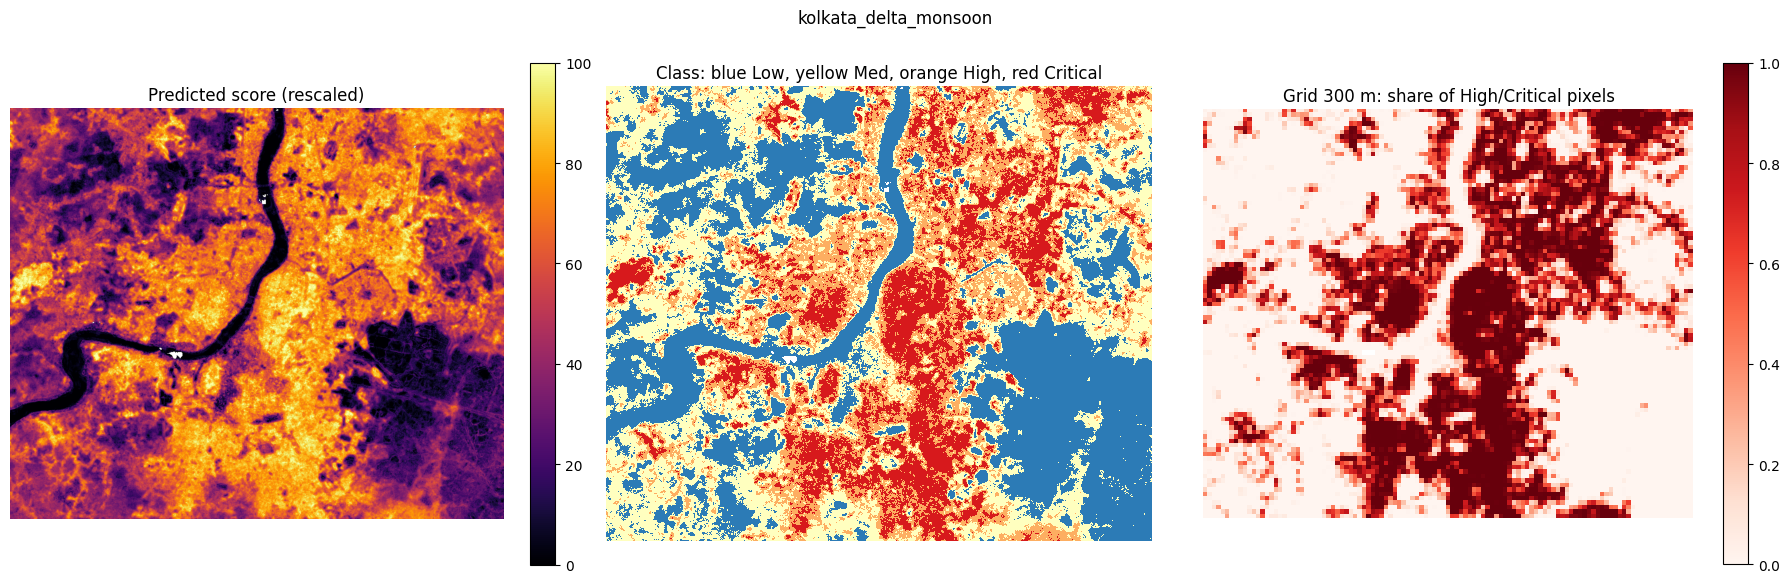


[kolkata_delta_monsoon] confusion (rows=true, cols=pred, rescaled):
             Low  Medium   High  Critical
Low       247895  104105  17625      2993
Medium     75550  152520  66776     27832
High        7010   49023  79008     52243
Critical    1487   18160  57451     70501


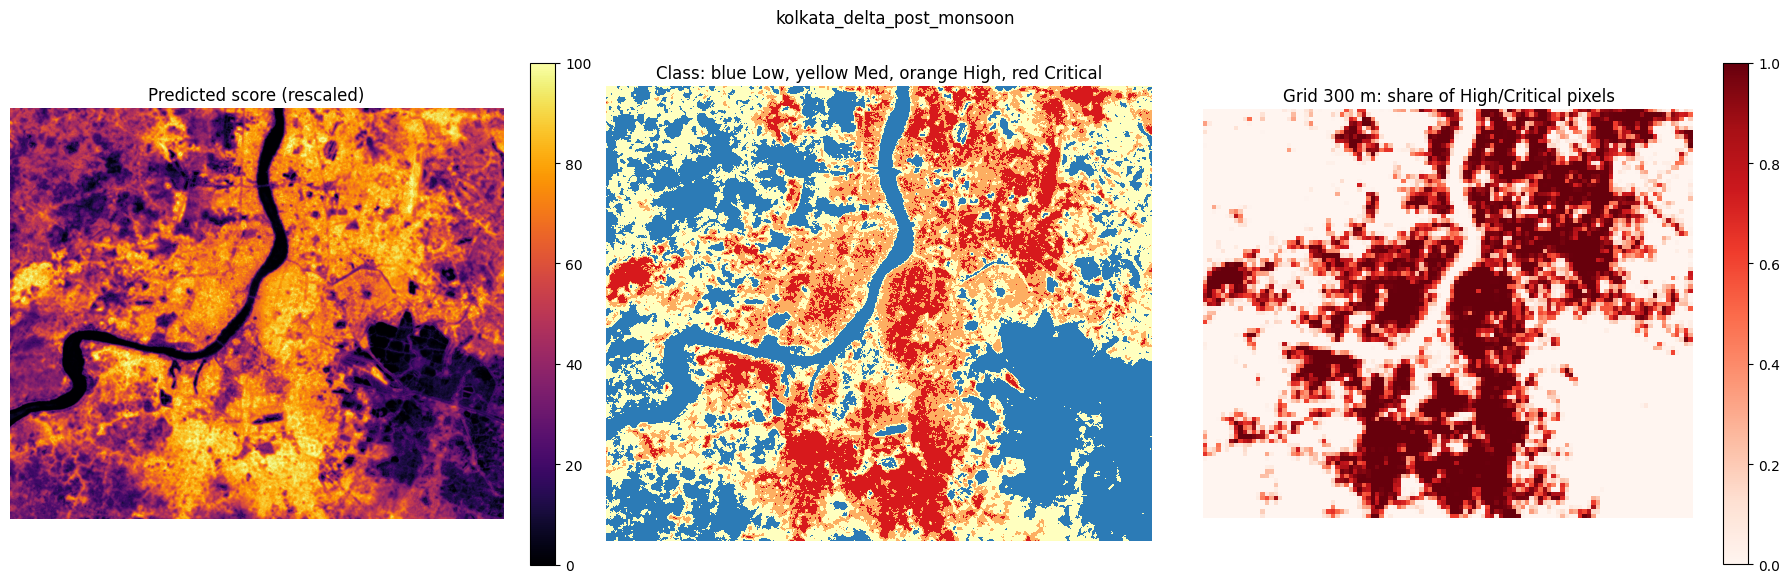


[kolkata_delta_post_monsoon] confusion (rows=true, cols=pred, rescaled):
             Low  Medium   High  Critical
Low       270499   65649    815        61
Medium     55121  198848  91112     31641
High        3231   40425  87767     65394
Critical     739   14403  53485     54602


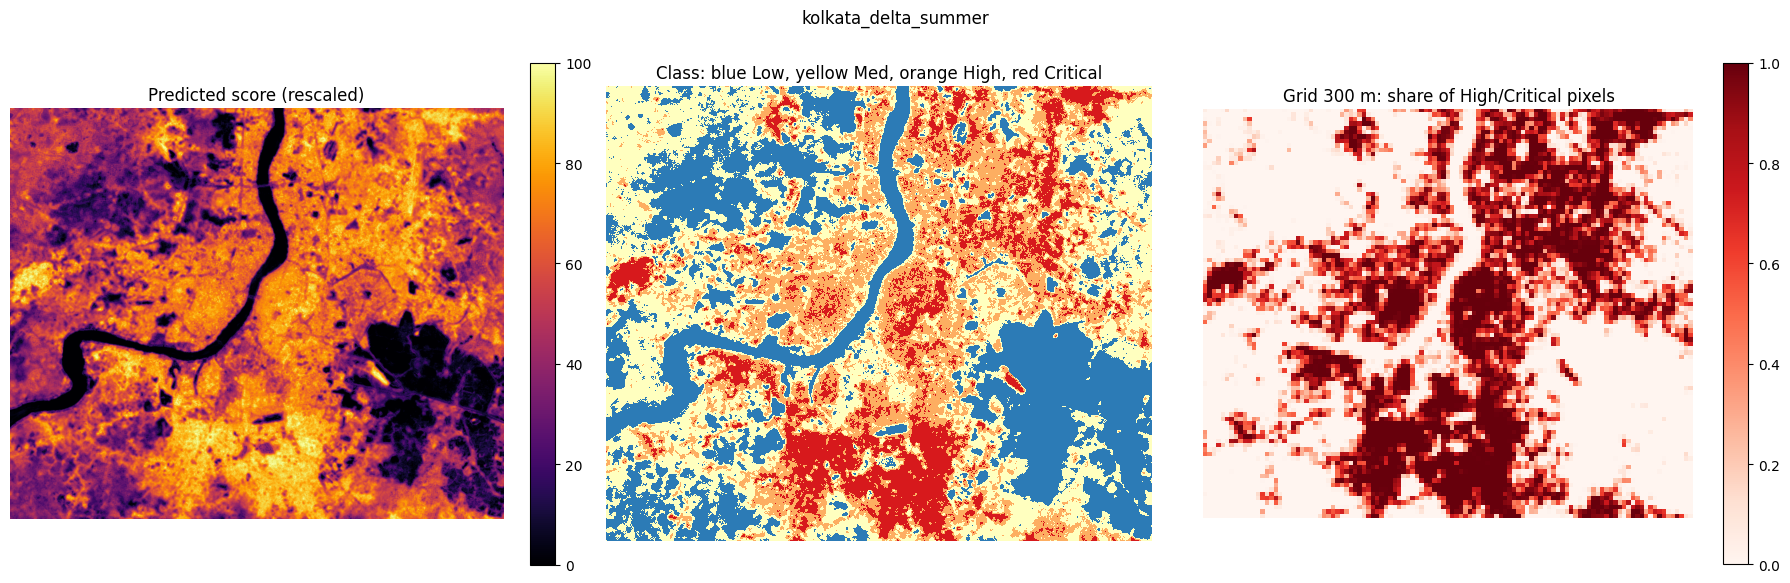


[kolkata_delta_summer] confusion (rows=true, cols=pred, rescaled):
             Low  Medium   High  Critical
Low       237236   57383    602        86
Medium     55151  232636  95770     19338
High        2879   52987  96513     64914
Critical     402   16404  60183     41308


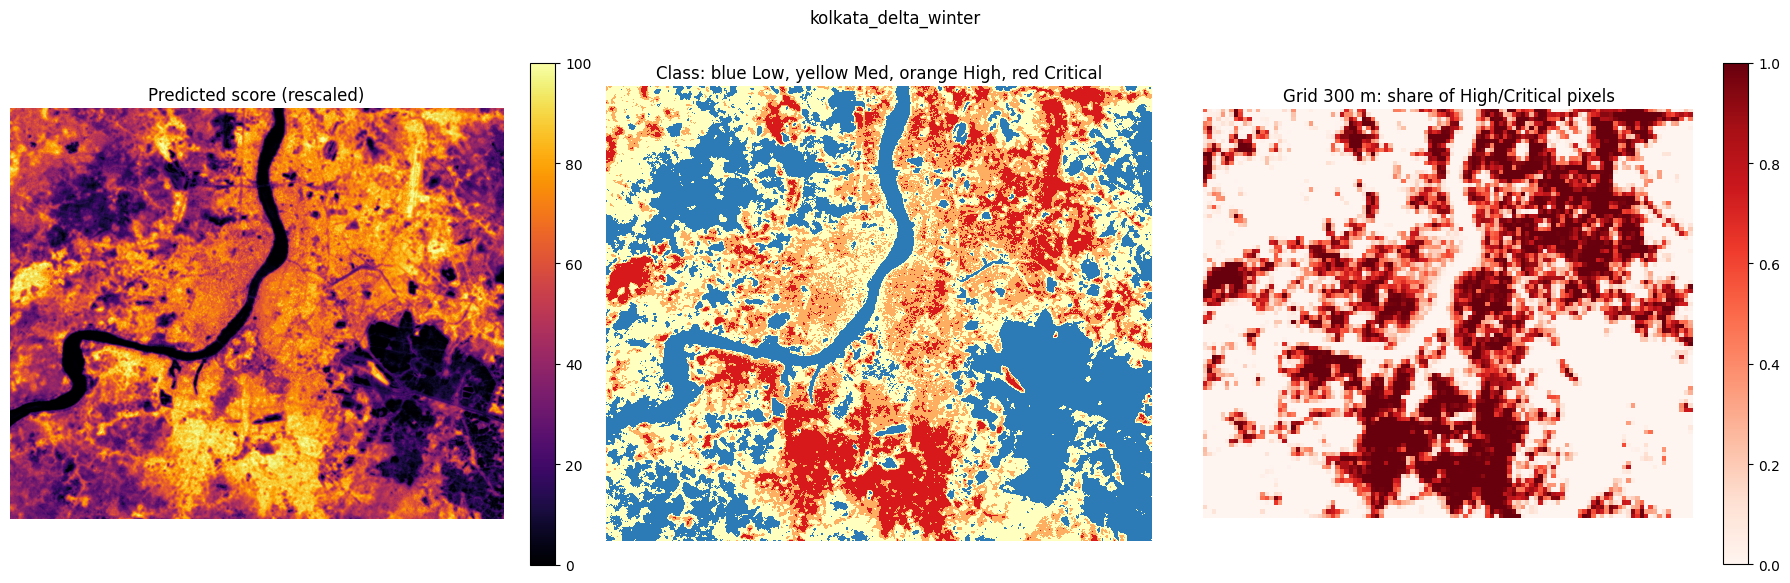


[kolkata_delta_winter] confusion (rows=true, cols=pred, rescaled):
             Low  Medium    High  Critical
Low       234491   57221    2387       439
Medium     69320  216323  114095     43034
High        6267   46546   72350     56117
Critical    1325   27225   50424     36228

=== SUMMARY (copy this block back to me) ===
         city       season  n_pixels  pct_low  pct_med  pct_high  pct_crit  grid_cells  hotspot_cells  raw_r2  raw_pearson  raw_rmse  raw_macro_f1  raw_qwk  raw_crit_recall  raw_hot_precision  raw_hot_recall  raw_hot_f1  rescaled_r2  rescaled_pearson  rescaled_rmse  rescaled_macro_f1  rescaled_qwk  rescaled_crit_recall  rescaled_hot_precision  rescaled_hot_recall  rescaled_hot_f1
kolkata_delta      monsoon   1033263   32.262   31.389    21.438    14.911       10320           3764   0.465        0.731    17.725         0.464    0.626            0.330              0.656           0.834       0.734        0.450             0.731         17.970              0.508    

In [ ]:
# ---------------------------------------------------------------------------
# UHI hotspot INFERENCE on a held-out city  --  prediction never touches LST.
#
# Paste into a NEW Colab cell and run AFTER the v3 training cell in the same
# session. It reuses: focal_mean_std, dist_to, scene_rank, scene_robust_z,
# parse_name, WINDOWS, PIX_M, _NB, SEASONS, THRESHOLDS, CLASS_NAMES, MIN_VALID_OBS.
#
# Pipeline per scene:
#   bands (NDVI NDBI MNDWI Elevation doy_sin doy_cos) -> full-scene features
#   -> model.predict -> per-scene rescale -> classes -> grid cells
# LST is read ONLY afterwards, in evaluate_vs_lst(), to score the result.
# ---------------------------------------------------------------------------
import os, glob, random, gc, warnings
import numpy as np
import pandas as pd
import rasterio
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import (r2_score, mean_squared_error, f1_score,
                             cohen_kappa_score, confusion_matrix)

HELDOUT_DIR = "/content/drive/MyDrive/UHI_Project/EarthEngine_Exports_HeldOut"
MODEL_PATH = "/content/drive/MyDrive/UHI_Project/models/uhi_model_v2.joblib"
OUT_DIR = "/content/drive/MyDrive/UHI_Project/inference_out"
CITY = None          # None = pick a random held-out city; or e.g. "pune_deccan"
CELL_M = 300         # heat-grid cell size in metres (multiple of 30)
HOT_FRAC = 0.5       # a grid cell is a hotspot if >= this share of its pixels are High/Critical
os.makedirs(OUT_DIR, exist_ok=True)


# ---------------------------------------------------------------------------
# 1) Features (identical to build_scene, minus every LST dependency)
# ---------------------------------------------------------------------------
def build_features_nolst(path):
    city, season = parse_name(path)
    need = ["NDVI", "NDBI", "MNDWI", "Elevation", "doy_sin", "doy_cos"]
    with rasterio.open(path) as ds:
        names = list(ds.descriptions)
        miss = [n for n in need if n not in names]
        if miss:
            raise ValueError(f"{os.path.basename(path)} lacks bands {miss}")
        b = {n: ds.read(names.index(n) + 1).astype(np.float32) for n in need}
        transform, crs = ds.transform, ds.crs
    H, W = b["NDVI"].shape

    ndvi, ndbi, mndwi, elev = b["NDVI"], b["NDBI"], b["MNDWI"], b["Elevation"]
    ok_idx = np.isfinite(ndvi) & np.isfinite(ndbi) & np.isfinite(mndwi)
    for a in (ndvi, ndbi, mndwi):
        a[~ok_idx] = np.nan

    F = {"NDVI": ndvi, "NDBI": ndbi, "MNDWI": mndwi, "Elevation": elev}
    F["BUI"] = ndbi - ndvi
    F["NDVI_x_NDBI"] = ndvi * ndbi

    for k in WINDOWS:
        for nm, a in (("NDVI", ndvi), ("NDBI", ndbi), ("MNDWI", mndwi), ("BUI", F["BUI"])):
            mu, sd = focal_mean_std(a, k)
            F[f"{nm}_mean_{k}"] = mu
            if k in (3, 7, 15):
                F[f"{nm}_std_{k}"] = sd
    for nm in ("NDVI", "NDBI"):
        F[f"d_{nm}_vs_31"] = F[nm] - F[f"{nm}_mean_31"]
        F[f"d_{nm}_vs_scene"] = F[nm] - np.nanmedian(F[nm])

    emu, _ = focal_mean_std(elev, 31)
    F["d_Elevation_vs_31"] = elev - emu
    F["d_Elevation_vs_scene"] = elev - np.nanmedian(elev)
    gy, gx = np.gradient(elev, PIX_M)
    F["slope"] = np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)

    F["dist_water_m"] = dist_to(np.nan_to_num(mndwi, nan=-1) > 0.1)
    F["dist_veg_m"] = dist_to(np.nan_to_num(ndvi, nan=0) > 0.5)
    F["dist_built_m"] = dist_to(np.nan_to_num(F["BUI"], nan=-9) >
                                np.nanpercentile(F["BUI"], 85))
    bui_s, _ = focal_mean_std(F["BUI"], 31)
    thr = np.nanpercentile(bui_s, 95)
    rr, cc = np.where(np.nan_to_num(bui_s, nan=-9) >= thr)
    r0, c0 = rr.mean(), cc.mean()
    R, C = np.indices((H, W))
    F["dist_core_m"] = (np.hypot(R - r0, C - c0) * PIX_M).astype(np.float32)

    F["doy_sin"], F["doy_cos"] = b["doy_sin"], b["doy_cos"]

    # scene-relative features (whole scene, as in training)
    for nm in ["NDVI", "NDBI", "MNDWI", "BUI", "Elevation", "dist_core_m", "dist_built_m"] + \
              [f"{n}_mean_{k}" for n in _NB for k in WINDOWS]:
        F[f"pr_{nm}"] = scene_rank(F[nm], ok_idx)
    for nm in ["NDVI", "NDBI", "MNDWI", "BUI",
               "NDVI_mean_15", "NDBI_mean_15", "MNDWI_mean_15", "BUI_mean_15"]:
        F[f"z_{nm}"] = scene_robust_z(F[nm], ok_idx)

    # scene-level descriptors (only used if the saved model's feature set needs them)
    nd, nb, mw, bu = ndvi[ok_idx], ndbi[ok_idx], mndwi[ok_idx], F["BUI"][ok_idx]
    q = lambda x: float(np.subtract(*np.percentile(x, [75, 25])))
    ev = elev[ok_idx]
    desc = {
        "sc_med_NDVI": np.median(nd), "sc_med_NDBI": np.median(nb),
        "sc_med_MNDWI": np.median(mw), "sc_med_BUI": np.median(bu),
        "sc_iqr_NDVI": q(nd), "sc_iqr_NDBI": q(nb),
        "sc_frac_water": (mw > 0.1).mean(), "sc_frac_veg": (nd > 0.5).mean(),
        "sc_frac_built": (bu > 0).mean(),
        "sc_elev_range": np.percentile(ev, 95) - np.percentile(ev, 5),
        "sc_corr_NDVI_NDBI": np.corrcoef(nd[::7], nb[::7])[0, 1],
        "sc_valid_frac": ok_idx.mean(),
    }

    # valid = every feature finite (NO LST condition)
    valid = np.ones((H, W), bool)
    for a in F.values():
        valid &= np.isfinite(a)
    r, c = np.where(valid)
    df = pd.DataFrame({k: v[valid] for k, v in F.items()})
    for k, v in desc.items():
        df[k] = np.float32(v)
    meta = dict(city=city, season=season, shape=(H, W), valid=valid,
                rc=(r, c), transform=transform, crs=crs)
    return df, meta


# ---------------------------------------------------------------------------
# 2) Predict + classify one scene
# ---------------------------------------------------------------------------
def rescale_scene(p):
    """Target is a within-scene z-score (mean 50, sd 25): force predictions to match."""
    return np.clip(50 + 25 * (p - p.mean()) / max(p.std(), 1e-6), 0, 100).astype(np.float32)


def predict_scene(path, bundle):
    model, FEATS, tuned = bundle["model"], bundle["features"], bundle["tuned_thresholds"]
    df, meta = build_features_nolst(path)
    for s in SEASONS:
        df[f"season_{s}"] = np.float32(meta["season"] == s)
    miss = [c for c in FEATS if c not in df.columns]
    assert not miss, f"missing features: {miss}"

    p_raw = np.clip(model.predict(df[FEATS].to_numpy(np.float32)), 0, 100).astype(np.float32)
    p_res = rescale_scene(p_raw)
    cls_raw = np.digitize(p_raw, tuned).astype(np.float32)
    cls_res = np.digitize(p_res, THRESHOLDS).astype(np.float32)

    H, W = meta["shape"]
    r, c = meta["rc"]
    grids = {}
    for name, v in (("score_raw", p_raw), ("score_rescaled", p_res),
                    ("class_raw", cls_raw), ("class_rescaled", cls_res)):
        g = np.full((H, W), np.nan, np.float32)
        g[r, c] = v
        grids[name] = g
    return dict(meta=meta, **grids)


# ---------------------------------------------------------------------------
# 3) Heat-grid aggregation
# ---------------------------------------------------------------------------
def to_grid(score, cls, transform, cell_m=CELL_M, hot_frac=HOT_FRAC):
    k = int(round(cell_m / PIX_M))
    H, W = score.shape
    gh, gw = -(-H // k), -(-W // k)
    pad = ((0, gh * k - H), (0, gw * k - W))
    s = np.pad(score, pad, constant_values=np.nan).reshape(gh, k, gw, k)
    hot = np.where(np.isfinite(score), (cls >= 2).astype(np.float32), np.nan)
    hot = np.pad(hot, pad, constant_values=np.nan).reshape(gh, k, gw, k)
    n = np.isfinite(s).sum((1, 3))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mean_score = np.nanmean(s, (1, 3))
        hot_share = np.nanmean(hot, (1, 3))
    thin = n < 0.5 * k * k                     # skip cells that are mostly empty
    mean_score[thin], hot_share[thin] = np.nan, np.nan
    ii, jj = np.indices((gh, gw))
    x = transform.c + (jj + 0.5) * k * transform.a
    y = transform.f + (ii + 0.5) * k * transform.e
    out = pd.DataFrame(dict(row=ii.ravel(), col=jj.ravel(), x=x.ravel(), y=y.ravel(),
                            n_pix=n.ravel(), mean_score=mean_score.ravel(),
                            hot_share=hot_share.ravel()))
    out = out[np.isfinite(out["mean_score"])].reset_index(drop=True)
    out["is_hotspot"] = out["hot_share"] >= hot_frac
    return out, hot_share


# ---------------------------------------------------------------------------
# 4) Evaluation only: LST is read here, never used for prediction
# ---------------------------------------------------------------------------
def _m(y, p, thr):
    yc, pc = np.digitize(y, THRESHOLDS), np.digitize(p, thr)
    hy, hp = yc >= 2, pc >= 2
    tp = (hy & hp).sum()
    return dict(r2=r2_score(y, p), pearson=float(np.corrcoef(y, p)[0, 1]),
                rmse=float(np.sqrt(mean_squared_error(y, p))),
                macro_f1=f1_score(yc, pc, average="macro"),
                qwk=cohen_kappa_score(yc, pc, weights="quadratic"),
                crit_recall=float(((pc == 3) & (yc == 3)).sum() / max((yc == 3).sum(), 1)),
                hot_precision=float(tp / max(hp.sum(), 1)),
                hot_recall=float(tp / max(hy.sum(), 1)),
                hot_f1=float(2 * tp / max(hy.sum() + hp.sum(), 1)))


def evaluate_vs_lst(path, res, tuned):
    with rasterio.open(path) as ds:
        names = list(ds.descriptions)
        if not all(n in names for n in ("LST", "Valid_Observation_Count", "Quality_Score")):
            return None
        rd = lambda n: ds.read(names.index(n) + 1).astype(np.float32)
        lst, nvalid, qs = rd("LST"), rd("Valid_Observation_Count"), rd("Quality_Score")
    lst[(lst < -10) | (lst > 70)] = np.nan
    lst[nvalid < MIN_VALID_OBS] = np.nan
    v = res["meta"]["valid"] & np.isfinite(lst) & (qs >= 0)
    if v.sum() < 1000:
        return None
    L = lst[v]
    mu, sd = L.mean(), L.std()
    y = np.clip((L - (mu - 2 * sd)) / (4 * sd) * 100, 0, 100)
    out = {}
    for tag, key, thr in (("raw", "score_raw", tuned), ("rescaled", "score_rescaled", THRESHOLDS)):
        out[tag] = _m(y, res[key][v], thr)
    out["_cm"] = confusion_matrix(np.digitize(y, THRESHOLDS),
                                  np.digitize(res["score_rescaled"][v], THRESHOLDS))
    out["_n"] = int(v.sum())
    return out


# ---------------------------------------------------------------------------
# 5) Outputs: GeoTIFF, grid CSV, preview PNG
# ---------------------------------------------------------------------------
def save_outputs(res, grid_df, hot_share, tag):
    meta = res["meta"]
    H, W = meta["shape"]
    stack = [res["score_raw"], res["score_rescaled"], res["class_rescaled"]]
    with rasterio.open(os.path.join(OUT_DIR, f"{tag}_pred.tif"), "w", driver="GTiff",
                       height=H, width=W, count=3, dtype="float32", crs=meta["crs"],
                       transform=meta["transform"], nodata=-9999.0, compress="lzw") as dst:
        for i, (arr, nm) in enumerate(zip(stack, ["score_raw", "score_rescaled", "class_rescaled"]), 1):
            dst.write(np.where(np.isfinite(arr), arr, -9999.0).astype(np.float32), i)
            dst.set_band_description(i, nm)
    grid_df.to_csv(os.path.join(OUT_DIR, f"{tag}_grid.csv"), index=False)

    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    im0 = ax[0].imshow(res["score_rescaled"], cmap="inferno", vmin=0, vmax=100)
    ax[0].set_title("Predicted score (rescaled)"); plt.colorbar(im0, ax=ax[0], fraction=0.046)
    cmap = ListedColormap(["#2c7bb6", "#ffffbf", "#fdae61", "#d7191c"])
    ax[1].imshow(res["class_rescaled"], cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
    ax[1].set_title("Class: blue Low, yellow Med, orange High, red Critical")
    im2 = ax[2].imshow(hot_share, cmap="Reds", vmin=0, vmax=1, interpolation="nearest")
    ax[2].set_title(f"Grid {CELL_M} m: share of High/Critical pixels"); plt.colorbar(im2, ax=ax[2], fraction=0.046)
    for a in ax:
        a.axis("off")
    fig.suptitle(tag)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"{tag}_preview.png"), dpi=110)
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------------
# 6) Run: random held-out city, all four seasons
# ---------------------------------------------------------------------------
bundle = joblib.load(MODEL_PATH)
try:
    bundle["model"].set_params(device="cpu")
except Exception:
    pass
print("model feature set:", bundle.get("config", {}).get("feature_set"),
      "| n_features:", len(bundle["features"]))

by_city = {}
for f in sorted(glob.glob(os.path.join(HELDOUT_DIR, "*.tif"))):
    cty, _ = parse_name(f)
    by_city.setdefault(cty, []).append(f)
city = CITY or random.choice(sorted(by_city))
print("held-out cities available:", sorted(by_city))
print("RUNNING CITY:", city)

rows = []
for path in by_city[city]:
    res = predict_scene(path, bundle)
    meta = res["meta"]
    tag = f"{meta['city']}_{meta['season']}"
    grid_df, hot_share = to_grid(res["score_rescaled"], res["class_rescaled"], meta["transform"])
    save_outputs(res, grid_df, hot_share, tag)

    cls = res["class_rescaled"][np.isfinite(res["class_rescaled"])]
    row = dict(city=meta["city"], season=meta["season"], n_pixels=len(cls),
               pct_low=(cls == 0).mean() * 100, pct_med=(cls == 1).mean() * 100,
               pct_high=(cls == 2).mean() * 100, pct_crit=(cls == 3).mean() * 100,
               grid_cells=len(grid_df), hotspot_cells=int(grid_df["is_hotspot"].sum()))
    ev = evaluate_vs_lst(path, res, bundle["tuned_thresholds"])
    if ev:
        for variant in ("raw", "rescaled"):
            for k, v in ev[variant].items():
                row[f"{variant}_{k}"] = v
        print(f"\n[{tag}] confusion (rows=true, cols=pred, rescaled):")
        print(pd.DataFrame(ev["_cm"], index=CLASS_NAMES, columns=CLASS_NAMES))
    rows.append(row)
    del res
    gc.collect()

summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(OUT_DIR, f"{city}_summary.csv"), index=False)
pd.set_option("display.width", 250, "display.max_columns", 50)
print("\n=== SUMMARY (copy this block back to me) ===")
print(summary.round(3).to_string(index=False))
print("\noutputs in:", OUT_DIR)

### THE MODEL IS COMPLETE
###  R2 score - 0.60 (im sory)
##### Required bands: NDVI, NDBI, MNDWI, Elevation, doy_sin, doy_cos, with those exact band names, on a 30 m grid in a metric projection using earth engine
#####

## final script for prediction (fix the path for model, output and input first)

In [2]:

# CELL 1: USER SETTINGS

CITY = "pune_deccan"

# [min longitude, min latitude, max longitude, max latitude]
AOI = [73.70, 18.35, 74.00, 18.70]

# The exact date to analyze
TARGET_DATE = "2024-05-15"

# Used for model season indicators and output filenames.
# This must match a season category supported by your model.
SEASON = "summer"

GEE_PROJECT = "landsat89-509617"
DRIVE_FOLDER = "EarthEngine_SingleDate"

MODEL_PATH = (
    "/content/drive/MyDrive/UHI_Project/"
    "models/uhi_model_v2.joblib"
)

OUT_DIR = (
    "/content/drive/MyDrive/UHI_Project/"
    f"inference_out/{CITY}_{TARGET_DATE}"
)

CELL_M = 300
HOT_FRAC = 0.50
MIN_VALID_OBS = 1

# Optional minimum number of valid observations.
# A single-date image usually has one valid observation per clear pixel.
MIN_CLEAR_PIXELS = 1000

os.makedirs(OUT_DIR, exist_ok=True) if "os" in globals() else None

print("City:", CITY)
print("Date:", TARGET_DATE)
print("AOI:", AOI)
print("Season label:", SEASON)
print("Output:", OUT_DIR)


City: pune_deccan
Date: 2024-05-15
AOI: [73.7, 18.35, 74.0, 18.7]
Season label: summer
Output: /content/drive/MyDrive/UHI_Project/inference_out/pune_deccan_2024-05-15


In [4]:

# CELL 2: AUTOMATIC NEAREST-DATE LANDSAT EXPORT

import ee
import os
import time
import glob
import math
from datetime import date, timedelta

# Preserve the originally requested date
REQUESTED_DATE = TARGET_DATE

SEARCH_DAYS = 30
MIN_VALID_PIXELS = 100

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)

aoi = ee.Geometry.BBox(*AOI)
requested = date.fromisoformat(REQUESTED_DATE)

def prepare_landsat(img):
    qa = img.select("QA_PIXEL")

    clear = (
        qa.bitwiseAnd(1 << 1).eq(0)
        .And(qa.bitwiseAnd(1 << 3).eq(0))
        .And(qa.bitwiseAnd(1 << 4).eq(0))
        .And(qa.bitwiseAnd(1 << 5).eq(0))
    )

    optical = (
        img.select(["SR_B3", "SR_B4", "SR_B5", "SR_B6"])
        .multiply(0.0000275)
        .add(-0.2)
        .rename(["Green", "Red", "NIR", "SWIR1"])
    )

    lst = (
        img.select("ST_B10")
        .multiply(0.00341802)
        .add(149.0)
        .subtract(273.15)
        .rename("LST")
    )

    valid = clear.And(img.select("ST_B10").mask())

    return (
        optical.addBands(lst)
        .updateMask(valid)
        .copyProperties(img, ["system:time_start"])
    )


def get_collection(start_date, end_date):
    start_ee = ee.Date(start_date.isoformat())
    end_ee = ee.Date(end_date.isoformat())

    l8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start_ee, end_ee)
    )

    l9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(aoi)
        .filterDate(start_ee, end_ee)
    )

    return l8.merge(l9)


# 1. Search around the requested date.
search_start = requested - timedelta(days=SEARCH_DAYS)
search_end = requested + timedelta(days=SEARCH_DAYS + 1)

search_collection = get_collection(search_start, search_end)
scene_info = search_collection.aggregate_array(
    "system:time_start"
).getInfo()

if not scene_info:
    raise RuntimeError(
        f"No Landsat 8/9 scenes intersect the AOI within "
        f"{SEARCH_DAYS} days of {REQUESTED_DATE}. "
        "Increase SEARCH_DAYS or check the AOI."
    )

# Get unique acquisition dates.
candidate_dates = sorted({
    date.fromtimestamp(ms / 1000).isoformat()
    for ms in scene_info
}, key=lambda d: (
    abs((date.fromisoformat(d) - requested).days),
    date.fromisoformat(d)
))

print("Requested date:", REQUESTED_DATE)
print("Candidate acquisition dates:", len(candidate_dates))

# 2. Test dates nearest-first and select the first with enough
# cloud-masked valid thermal pixels.
ACTUAL_DATE = None
raw = None
clean = None

for candidate in candidate_dates:
    day = date.fromisoformat(candidate)
    day_raw = get_collection(day, day + timedelta(days=1))
    day_clean = day_raw.map(prepare_landsat)

    valid_count_img = day_clean.select("LST").count()

    count_result = valid_count_img.reduceRegion(
        reducer=ee.Reducer.count(),
        geometry=aoi,
        scale=120,
        maxPixels=1e8,
        bestEffort=True,
        tileScale=4
    ).getInfo()

    valid_pixels = count_result.get("LST", 0) or 0
    offset = (day - requested).days

    print(
        f"{candidate}: {valid_pixels} valid sampled pixels "
        f"(offset {offset:+d} days)"
    )

    if valid_pixels >= MIN_VALID_PIXELS:
        ACTUAL_DATE = candidate
        raw = day_raw
        clean = day_clean
        break

if ACTUAL_DATE is None:
    raise RuntimeError(
        "No candidate date had enough valid thermal pixels. "
        "Increase SEARCH_DAYS, lower MIN_VALID_PIXELS cautiously, "
        "or use a larger AOI."
    )

# Downstream cells will use the actual acquisition date.
TARGET_DATE = ACTUAL_DATE

print("\nSelected acquisition date:", ACTUAL_DATE)
print("Difference from requested date:",
      (date.fromisoformat(ACTUAL_DATE) - requested).days, "days")

# 3. Build a composite from this acquisition date only.
# If multiple scenes occur on the same date, combine only those
# same-day scenes. No observations from other dates are included.
composite = (
    clean.select(["LST", "Green", "Red", "NIR", "SWIR1"])
    .median()
    .clip(aoi)
)

ndvi = composite.normalizedDifference(
    ["NIR", "Red"]
).rename("NDVI")

ndbi = composite.normalizedDifference(
    ["SWIR1", "NIR"]
).rename("NDBI")

mndwi = composite.normalizedDifference(
    ["Green", "SWIR1"]
).rename("MNDWI")

elevation = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
    .rename("Elevation")
    .clip(aoi)
)

valid_count = (
    clean.select("LST").count()
    .rename("Valid_Observation_Count")
)

available_count = (
    raw.select("ST_B10").count()
    .rename("Observation_Count")
)

quality = (
    valid_count.divide(available_count.max(1))
    .rename("Quality_Score")
)

# Use the ACTUAL acquisition date for temporal features.
doy = date.fromisoformat(ACTUAL_DATE).timetuple().tm_yday
angle = 2 * math.pi * doy / 365.25

temporal = ee.Image.constant([
    math.sin(angle), math.cos(angle)
]).rename(["doy_sin", "doy_cos"])

stack = (
    composite.select("LST")
    .addBands(ndvi)
    .addBands(ndbi)
    .addBands(mndwi)
    .addBands(elevation)
    .addBands(temporal)
    .addBands(quality)
    .addBands(valid_count)
    .addBands(available_count)
    .toFloat()
    .clip(aoi)
)

prefix = f"uhi_features_{CITY}_{ACTUAL_DATE}"

task = ee.batch.Export.image.toDrive(
    image=stack,
    description=f"HeatGrid_{CITY}_{ACTUAL_DATE}",
    folder=DRIVE_FOLDER,
    fileNamePrefix=prefix,
    region=aoi,
    scale=30,
    crs="EPSG:4326",
    maxPixels=1e10,
    fileFormat="GeoTIFF"
)

task.start()
print("Export started:", task.id)

deadline = time.time() + 180 * 60

while time.time() < deadline:
    status = task.status()
    state = status.get("state", "UNKNOWN")
    print("Export status:", state)

    if state == "COMPLETED":
        break

    if state in ("FAILED", "CANCELLED"):
        raise RuntimeError(f"Export failed: {status}")

    time.sleep(15)
else:
    raise TimeoutError(
        "Export is still running. Check Earth Engine Tasks "
        "before starting another export."
    )

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

search_pattern = os.path.join(
    "/content/drive/MyDrive",
    DRIVE_FOLDER,
    prefix + "*.tif"
)

tif_matches = []
for _ in range(30):
    tif_matches = glob.glob(search_pattern)
    if tif_matches:
        break
    time.sleep(2)

if not tif_matches:
    raise FileNotFoundError(
        "Export completed, but the GeoTIFF was not found: "
        + search_pattern
    )

TIF_PATH = tif_matches[0]

print("\nExport ready:", TIF_PATH)
print("Requested date:", REQUESTED_DATE)
print("Actual image date:", ACTUAL_DATE)


Requested date: 2024-05-15
Candidate acquisition dates: 7
2024-05-18: 90055 valid sampled pixels (offset +3 days)

Selected acquisition date: 2024-05-18
Difference from requested date: 3 days
Export started: RC2VCVAFADGJ7SH2L4P4KIZT
Export status: READY
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: RUNNING
Export status: COMPLETED
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Export ready: /content/drive/MyDrive/EarthEngine_SingleDate/uhi_features_pune_deccan_2024-05-18.tif
Requested date: 2024-05-15
Actual image date: 2024-05-18


In [5]:

# CELL 3: LOAD MODEL AND BUILD FEATURES

import os
import numpy as np
import pandas as pd
import rasterio
import joblib
from scipy.ndimage import uniform_filter, distance_transform_edt
from scipy.stats import rankdata

bundle = joblib.load(MODEL_PATH)

model = bundle["model"]
FEATS = list(bundle["features"])

THRESHOLDS = np.asarray(
    bundle.get("thresholds", [37.5, 62.5, 78.0]),
    dtype=float
)

PIX_M = 30.0
WINDOWS = [3, 7, 15, 31]
_NB = ["NDVI", "NDBI", "MNDWI", "BUI"]

print("Loaded model.")
print("Feature count:", len(FEATS))
print("Model feature set:", bundle.get("config", {}).get("feature_set"))


def focal_mean_std(arr, k):
    valid = np.isfinite(arr).astype(np.float32)
    data = np.where(np.isfinite(arr), arr, 0).astype(np.float32)

    # Use zero padding and normalized convolution.
    count = uniform_filter(valid, size=k, mode="constant") * (k * k)
    total = uniform_filter(data, size=k, mode="constant") * (k * k)
    total2 = uniform_filter(data * data, size=k, mode="constant") * (k * k)

    mean = np.divide(
        total, count, out=np.full_like(total, np.nan), where=count > 0
    )
    second = np.divide(
        total2, count, out=np.full_like(total2, np.nan), where=count > 0
    )
    std = np.sqrt(np.maximum(second - mean * mean, 0))
    return mean.astype(np.float32), std.astype(np.float32)


def dist_to(mask):
    return (
        distance_transform_edt(~mask) * PIX_M
    ).astype(np.float32)


def scene_rank(arr, valid):
    out = np.full(arr.shape, np.nan, np.float32)
    ok = valid & np.isfinite(arr)

    if ok.any():
        out[ok] = (
            rankdata(arr[ok], method="average") / ok.sum()
        ).astype(np.float32)

    return out


def scene_robust_z(arr, valid):
    out = np.full(arr.shape, np.nan, np.float32)
    ok = valid & np.isfinite(arr)

    if ok.any():
        med = np.median(arr[ok])
        scale = 1.4826 * np.median(np.abs(arr[ok] - med))

        if scale < 1e-6:
            scale = np.std(arr[ok])

        out[ok] = (
            (arr[ok] - med) / scale if scale >= 1e-6
            else np.zeros(ok.sum())
        )

    return out


def build_features_nolst(path):
    with rasterio.open(path) as ds:
        names = list(ds.descriptions)

        required = [
            "NDVI", "NDBI", "MNDWI", "Elevation",
            "doy_sin", "doy_cos"
        ]
        missing = [n for n in required if n not in names]

        if missing:
            raise ValueError(f"Missing GeoTIFF bands: {missing}")

        b = {
            n: ds.read(names.index(n) + 1).astype(np.float32)
            for n in required
        }
        transform, crs = ds.transform, ds.crs

    ndvi, ndbi, mndwi, elev = (
        b["NDVI"], b["NDBI"], b["MNDWI"], b["Elevation"]
    )

    ok_idx = (
        np.isfinite(ndvi)
        & np.isfinite(ndbi)
        & np.isfinite(mndwi)
        & np.isfinite(elev)
    )

    for arr in (ndvi, ndbi, mndwi):
        arr[~ok_idx] = np.nan

    F = {
        "NDVI": ndvi,
        "NDBI": ndbi,
        "MNDWI": mndwi,
        "Elevation": elev,
    }

    F["BUI"] = ndbi - ndvi
    F["NDVI_x_NDBI"] = ndvi * ndbi

    for k in WINDOWS:
        for nm in ("NDVI", "NDBI", "MNDWI", "BUI"):
            mu, sd = focal_mean_std(F[nm], k)
            F[f"{nm}_mean_{k}"] = mu

            if k in (3, 7, 15):
                F[f"{nm}_std_{k}"] = sd

    for nm in ("NDVI", "NDBI"):
        F[f"d_{nm}_vs_31"] = F[nm] - F[f"{nm}_mean_31"]
        F[f"d_{nm}_vs_scene"] = F[nm] - np.nanmedian(F[nm])

    elev_mean, _ = focal_mean_std(elev, 31)
    F["d_Elevation_vs_31"] = elev - elev_mean
    F["d_Elevation_vs_scene"] = elev - np.nanmedian(elev)

    gy, gx = np.gradient(elev, PIX_M)
    F["slope"] = np.degrees(np.arctan(np.hypot(gx, gy))).astype(np.float32)

    F["dist_water_m"] = dist_to(np.nan_to_num(mndwi, nan=-1) > 0.1)
    F["dist_veg_m"] = dist_to(np.nan_to_num(ndvi, nan=0) > 0.5)

    bui = F["BUI"]
    bui_threshold = np.nanpercentile(bui[ok_idx], 85)
    F["dist_built_m"] = dist_to(
        np.nan_to_num(bui, nan=-9) > bui_threshold
    )

    bui_smooth, _ = focal_mean_std(bui, 31)
    finite_bui = bui_smooth[np.isfinite(bui_smooth)]

    if finite_bui.size:
        threshold = np.percentile(finite_bui, 95)
        rr, cc = np.where(
            np.nan_to_num(bui_smooth, nan=-9) >= threshold
        )

        R, C = np.indices(ndvi.shape)
        F["dist_core_m"] = (
            np.hypot(R - rr.mean(), C - cc.mean()) * PIX_M
        ).astype(np.float32)
    else:
        F["dist_core_m"] = np.full(ndvi.shape, np.nan, np.float32)

    F["doy_sin"] = b["doy_sin"]
    F["doy_cos"] = b["doy_cos"]

    for nm in (
        ["NDVI", "NDBI", "MNDWI", "BUI", "Elevation",
         "dist_core_m", "dist_built_m"]
        + [f"{n}_mean_{k}" for n in _NB for k in WINDOWS]
    ):
        if nm in F:
            F[f"pr_{nm}"] = scene_rank(F[nm], ok_idx)

    for nm in [
        "NDVI", "NDBI", "MNDWI", "BUI",
        "NDVI_mean_15", "NDBI_mean_15",
        "MNDWI_mean_15", "BUI_mean_15"
    ]:
        F[f"z_{nm}"] = scene_robust_z(F[nm], ok_idx)

    nd, nb = ndvi[ok_idx], ndbi[ok_idx]
    mw, bu, ev = mndwi[ok_idx], F["BUI"][ok_idx], elev[ok_idx]

    def iqr(x):
        return float(np.percentile(x, 75) - np.percentile(x, 25))

    desc = {
        "sc_med_NDVI": np.median(nd),
        "sc_med_NDBI": np.median(nb),
        "sc_med_MNDWI": np.median(mw),
        "sc_med_BUI": np.median(bu),
        "sc_iqr_NDVI": iqr(nd),
        "sc_iqr_NDBI": iqr(nb),
        "sc_frac_water": (mw > 0.1).mean(),
        "sc_frac_veg": (nd > 0.5).mean(),
        "sc_frac_built": (bu > 0).mean(),
        "sc_elev_range": np.percentile(ev, 95) - np.percentile(ev, 5),
        "sc_corr_NDVI_NDBI": (
            np.corrcoef(nd[::7], nb[::7])[0, 1]
            if len(nd[::7]) > 2 else 0.0
        ),
        "sc_valid_frac": ok_idx.mean(),
    }

    valid = ok_idx.copy()

    for arr in F.values():
        valid &= np.isfinite(arr)

    if valid.sum() < MIN_CLEAR_PIXELS:
        raise ValueError(
            f"Only {valid.sum()} valid pixels remain. "
            "Check clouds, AOI, and date."
        )

    df = pd.DataFrame({k: v[valid] for k, v in F.items()})

    for key, value in desc.items():
        df[key] = np.float32(value)

    for s in ["summer", "monsoon", "post_monsoon", "winter"]:
        df[f"season_{s}"] = np.float32(SEASON == s)

    missing = [f for f in FEATS if f not in df.columns]

    if missing:
        raise ValueError(
            "The trained model requires features that this feature "
            f"builder does not generate: {missing}. "
            "Copy the exact feature builder from your training pipeline."
        )

    meta = {
        "shape": valid.shape,
        "valid": valid,
        "rc": np.where(valid),
        "transform": transform,
        "crs": crs,
    }

    return df, meta


print("Feature-building functions are ready.")


Loaded model.
Feature count: 82
Model feature set: abs+rel
Feature-building functions are ready.


Running prediction...
Pixels to predict: 1449207
Features used: 82


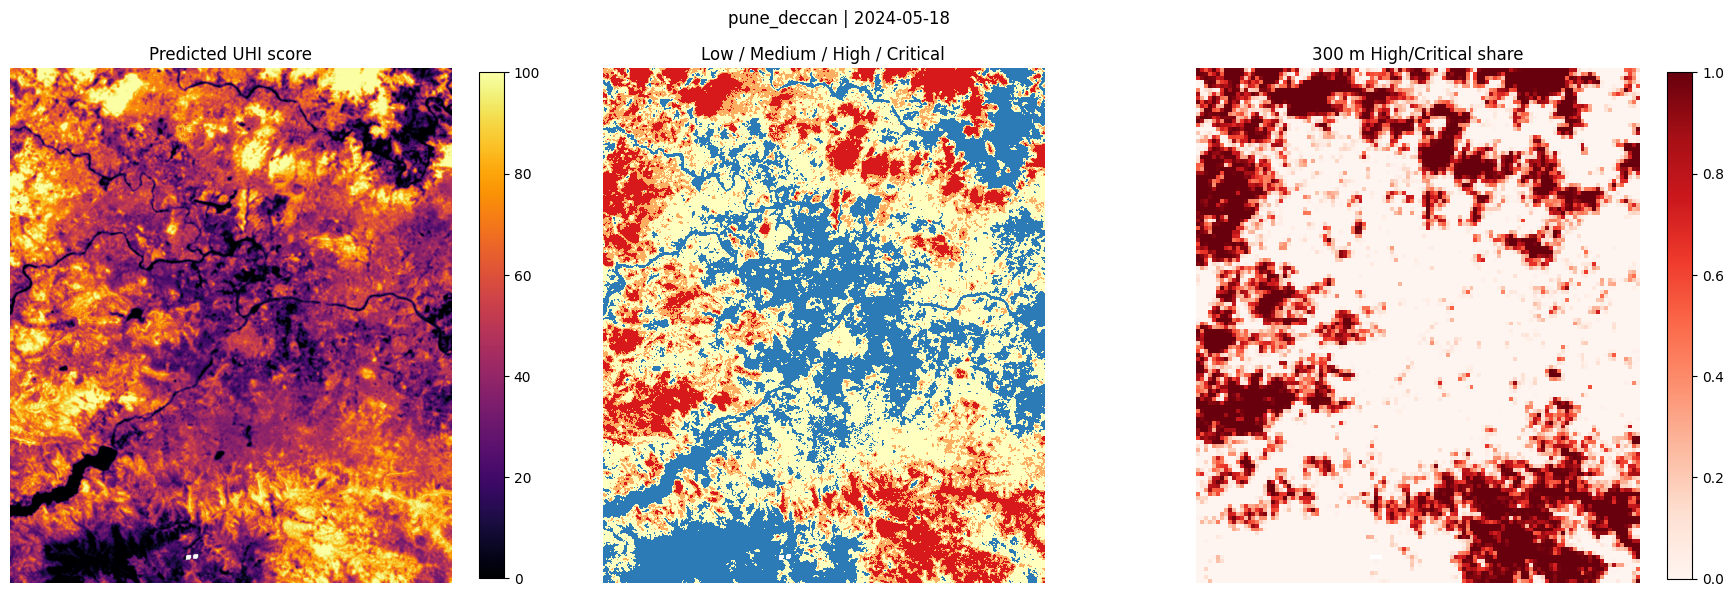


========== SINGLE-DATE UHI SUMMARY ==========
       city       date  valid_pixels  low_pct  medium_pct  high_pct  critical_pct  grid_cells  hotspot_cells
pune_deccan 2024-05-18       1449207   29.607      40.256    16.378        13.759       14557           4281

Files saved:
Prediction GeoTIFF: /content/drive/MyDrive/UHI_Project/inference_out/pune_deccan_2024-05-15/pune_deccan_2024-05-18_uhi_prediction.tif
Grid CSV: /content/drive/MyDrive/UHI_Project/inference_out/pune_deccan_2024-05-15/pune_deccan_2024-05-18_grid.csv
Summary CSV: /content/drive/MyDrive/UHI_Project/inference_out/pune_deccan_2024-05-15/pune_deccan_2024-05-18_summary.csv
Preview PNG: /content/drive/MyDrive/UHI_Project/inference_out/pune_deccan_2024-05-15/pune_deccan_2024-05-18_preview.png


In [6]:

# CELL 4: SINGLE-DATE UHI PREDICTION

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

df, meta = build_features_nolst(TIF_PATH)

# LST is NOT included in this feature matrix.
X = df[FEATS].to_numpy(dtype=np.float32)

print("Running prediction...")
print("Pixels to predict:", len(df))
print("Features used:", len(FEATS))

raw = np.clip(model.predict(X), 0, 100).astype(np.float32)

# Same within-scene normalization as your earlier inference code.
score = np.clip(
    50 + 25 * (raw - raw.mean()) / max(float(raw.std()), 1e-6),
    0, 100
).astype(np.float32)

classes = np.digitize(score, THRESHOLDS).astype(np.float32)

H, W = meta["shape"]
r, c = meta["rc"]

raw_map = np.full((H, W), np.nan, np.float32)
score_map = np.full((H, W), np.nan, np.float32)
class_map = np.full((H, W), np.nan, np.float32)

raw_map[r, c] = raw
score_map[r, c] = score
class_map[r, c] = classes

# Save three-band prediction GeoTIFF.
pred_path = os.path.join(
    OUT_DIR, f"{CITY}_{TARGET_DATE}_uhi_prediction.tif"
)

with rasterio.open(
    TIF_PATH
) as src:
    profile = src.profile.copy()

profile.update(
    count=3,
    dtype="float32",
    nodata=-9999.0,
    compress="lzw"
)

with rasterio.open(pred_path, "w", **profile) as dst:
    for i, (arr, name) in enumerate([
        (raw_map, "score_raw"),
        (score_map, "score_rescaled"),
        (class_map, "class_rescaled")
    ], start=1):
        dst.write(
            np.where(np.isfinite(arr), arr, -9999).astype(np.float32),
            i
        )
        dst.set_band_description(i, name)

# Aggregate to the requested heat-grid resolution.
def aggregate_grid(score_map, class_map, transform):
    k = CELL_M // 30
    H, W = score_map.shape

    gh = (H + k - 1) // k
    gw = (W + k - 1) // k

    pad = ((0, gh * k - H), (0, gw * k - W))

    s = np.pad(score_map, pad, constant_values=np.nan)

    hot = np.where(
        np.isfinite(score_map),
        (class_map >= 2).astype(np.float32),
        np.nan
    )
    hot = np.pad(hot, pad, constant_values=np.nan)

    s = s.reshape(gh, k, gw, k)
    hot = hot.reshape(gh, k, gw, k)

    n = np.isfinite(s).sum(axis=(1, 3))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mean_score = np.nanmean(s, axis=(1, 3))
        hot_share = np.nanmean(hot, axis=(1, 3))

    # Exclude cells with less than half their pixels valid.
    thin = n < 0.5 * k * k
    mean_score[thin] = np.nan
    hot_share[thin] = np.nan

    ii, jj = np.indices((gh, gw))

    # Cell-center coordinates in the GeoTIFF CRS.
    x = transform.c + (jj + 0.5) * k * transform.a
    y = transform.f + (ii + 0.5) * k * transform.e

    grid = pd.DataFrame({
        "row": ii.ravel(),
        "col": jj.ravel(),
        "x": x.ravel(),
        "y": y.ravel(),
        "valid_pixels": n.ravel(),
        "mean_score": mean_score.ravel(),
        "hot_share": hot_share.ravel()
    })

    grid = grid[np.isfinite(grid["mean_score"])].copy()
    grid["is_hotspot"] = grid["hot_share"] >= HOT_FRAC

    return grid.reset_index(drop=True), hot_share


grid_df, hot_share = aggregate_grid(
    score_map, class_map, meta["transform"]
)

grid_path = os.path.join(
    OUT_DIR, f"{CITY}_{TARGET_DATE}_grid.csv"
)
grid_df.to_csv(grid_path, index=False)

# Create preview.
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

im = ax[0].imshow(score_map, cmap="inferno", vmin=0, vmax=100)
ax[0].set_title("Predicted UHI score")
plt.colorbar(im, ax=ax[0], fraction=0.046)

cmap = ListedColormap([
    "#2c7bb6", "#ffffbf", "#fdae61", "#d7191c"
])
ax[1].imshow(
    class_map, cmap=cmap, vmin=0, vmax=3,
    interpolation="nearest"
)
ax[1].set_title("Low / Medium / High / Critical")

im2 = ax[2].imshow(hot_share, cmap="Reds", vmin=0, vmax=1)
ax[2].set_title(f"{CELL_M} m High/Critical share")
plt.colorbar(im2, ax=ax[2], fraction=0.046)

for a in ax:
    a.axis("off")

fig.suptitle(f"{CITY} | {TARGET_DATE}")
fig.tight_layout()

preview_path = os.path.join(
    OUT_DIR, f"{CITY}_{TARGET_DATE}_preview.png"
)
fig.savefig(preview_path, dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

# Summary
valid_classes = class_map[np.isfinite(class_map)]

summary = pd.DataFrame([{
    "city": CITY,
    "date": TARGET_DATE,
    "valid_pixels": len(valid_classes),
    "low_pct": 100 * np.mean(valid_classes == 0),
    "medium_pct": 100 * np.mean(valid_classes == 1),
    "high_pct": 100 * np.mean(valid_classes == 2),
    "critical_pct": 100 * np.mean(valid_classes == 3),
    "grid_cells": len(grid_df),
    "hotspot_cells": int(grid_df["is_hotspot"].sum())
}])

summary_path = os.path.join(
    OUT_DIR, f"{CITY}_{TARGET_DATE}_summary.csv"
)
summary.to_csv(summary_path, index=False)

print("\n========== SINGLE-DATE UHI SUMMARY ==========")
print(summary.round(3).to_string(index=False))

print("\nFiles saved:")
print("Prediction GeoTIFF:", pred_path)
print("Grid CSV:", grid_path)
print("Summary CSV:", summary_path)
print("Preview PNG:", preview_path)